# Virtual Humans Assignment

This assignment has three parts and 100 points in total.

| Part | Exercise | Topic | Points |
|---|---|---|---:|
| **1. Signed Distance Fields** | | | **30** |
| | 1 | Inside or outside? Ray parity | 11 |
| | 2 | Signed distance to the mesh | 9 |
| | 3 | Level sets | 10 |
| **2. Procrustes Analysis** | | | **26** |
| | 4 | Apply a similarity transformation | 3 |
| | 5 | Implement Procrustes analysis | 10 |
| | 6 | Noise | 4 |
| | Question 1 | Order of the transformations | 3 |
| | Question 2 | Reflection | 3 |
| | Question 3 | Permutation | 3 |
| **3. ICP for SMPL** | | | **44** |
| | 7 | Find correspondences | 4 |
| | 8 | Implement ICP | 10 |
| | 9 | ICP on SMPL models | 7 |
| | 10 | Fit SMPL to scans with ICP | 11 |
| | 11 | Pose prior | 7 |
| | 12 | Shape prior | 5 |

Each exercise lists what you have to do, and your code goes between `#### START OF YOUR SOLUTION ####` and `#### END YOUR SOLUTION ####`. Every exercise ends with an **Expected result** section, so you can check your work. Written answers are graded on your explanation, not on repeating the values.

The parts are independent, except that Part 3 uses functions from Part 2.


## Team members

Enter the full name and the matriculation number of every team member (at most three).

| Name | Matriculation number |
|---|---|
|  |  |
|  |  |
|  |  |


# Part 1: Signed Distance Fields (30 points)

**Goal**: for a signed distance field $f$, the value $f(\mathbf p)$ is the distance of $\mathbf p$ to the surface, the gradient $\nabla f(\mathbf p)$ is the surface normal direction, and one step $\mathbf q = \mathbf p - f(\mathbf p)\,\nabla f(\mathbf p)$ lands on the closest surface point. The lecture demo *Distance field queries* used analytic SDFs (a circle and a box). Here you build an SDF from the representation we actually have in practice: a **triangle mesh**. A sampled SDF grid like the one you will compute is exactly the supervision signal used by learned implicit human models (occupancy and SDF networks).

You will do three things:

- Exercise 1: test whether 3D points are inside a closed triangle mesh, using ray parity and the Möller–Trumbore ray–triangle intersection.
- Exercise 2: compute the signed distance to the mesh, as the minimum over triangles of a provided point–triangle distance, with the sign from Exercise 1, and evaluate it on a regular grid.
- Exercise 3: visualize the level sets of the SDF, with planar slices and marching-cubes iso-surfaces at several iso-values and grid resolutions.

**Rules for this part**

- Allowed: `numpy`, `matplotlib`, `skimage.measure.marching_cubes` for Exercise 3, and `scipy` only for things unrelated to distances (nothing from `scipy.spatial` here).
- Not allowed: any library function that computes mesh containment, point–mesh distance or signed distance (for example `trimesh.proximity`, `trimesh.contains`, `igl.signed_distance`, `pysdf`). You may use them only to cross-check your results.
- Do not change the provided code. In particular, do not change the colours, figure sizes, contour levels or camera angles: every correct solution produces the same figures, and this is how Exercise 3 is graded.
- The grid resolution is `GRID_N = 32`. If your code is vectorized, the full SDF takes about one minute on a laptop. You may try `GRID_N = 48` once everything works, but submit with 32.
- There are no written questions in this part. The sections marked *not graded* are extra reading.


**Run this cell. No code needed.**

In [ ]:
import hashlib
import importlib.util
import subprocess
import sys
import time

if importlib.util.find_spec('skimage') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-image'])

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from skimage import measure

GRID_N = 32            # SDF grid resolution per axis (32 for submission; 48 optional)
DOMAIN = 1.4           # grid covers [-DOMAIN, DOMAIN]^3; the mesh fits in [-1, 1]^3
LEVELS = np.round(np.arange(-0.4, 0.81, 0.1), 2)   # contour levels for slices
ISO_LEVELS = [-0.15, 0.0, 0.15, 0.30]               # iso-surfaces for marching cubes
SWEEP_N = [12, 20, 32]                               # grid resolutions for the sweep
RAY_DIR = np.array([0.3, 0.5, 0.81]); RAY_DIR /= np.linalg.norm(RAY_DIR)   # fixed ray direction for Exercise 1 (oblique on purpose)

PALETTE = {
    'inside':    '#a51e37',   # Tübingen red: inside / negative
    'outside':   '#3e5566',   # slate: outside / positive
    'surface':   '#000000',   # the zero level set
    'highlight': '#8f7b3c',   # gold: highlighted level set / closest point
    'mesh':      '#c9ced4',   # grey: mesh faces
    'levels':    'RdBu_r',    # diverging colormap for slice plots (negative = red, positive = blue)
    'iso':       ['#c9566d', '#c9ced4', '#c2ad66', '#7d95a6'],   # one colour per ISO_LEVELS entry (lighter tints so shading is visible)
}
VIEW = dict(elev=22, azim=-55)
SDF_STYLE = dict({'figure.dpi': 100, 'savefig.dpi': 100, 'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12,
                     'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11})   # only applied inside the figure helpers below

def _cam_dir():
    # unit vector from the scene centre towards the (fixed) camera, from VIEW
    e, a = np.radians(VIEW['elev']), np.radians(VIEW['azim'])
    return np.array([np.cos(e) * np.cos(a), np.cos(e) * np.sin(a), np.sin(e)])

def _style3d(ax, title=None, lim=DOMAIN, zoom=1.16):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_box_aspect((1, 1, 1), zoom=zoom); ax.view_init(**VIEW)
    ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_zticks([-1, 0, 1])
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):          # light, unobtrusive box: no pane fill, pale grid
        axis.set_pane_color((1.0, 1.0, 1.0, 0.0)); axis.pane.set_edgecolor('#d5d9dd')
        axis._axinfo['grid'].update(color='#d9dde1', linewidth=0.7, linestyle='-')
        axis.line.set_color('#b0b6bc')
    ax.tick_params(colors='#666666', labelsize=10, pad=-2); ax.patch.set_alpha(0.0)   # transparent patch: neighbouring panels do not cover tick labels
    ax.set_xlabel('x', labelpad=2, color='#444444'); ax.set_ylabel('y', labelpad=2, color='#444444'); ax.set_zlabel('z', labelpad=-4, color='#444444')
    if title: ax.set_title(title, pad=2, fontsize=13)

def _shade(V, F, color, light=None):
    # per-face shading (key light from the upper left of the camera + soft fill from the camera + small highlight)
    # so that bumps and dents are readable; normals are flipped towards the camera, so the face orientation does not matter
    T = V[F]; n = np.cross(T[:, 1] - T[:, 0], T[:, 2] - T[:, 0]); n /= np.linalg.norm(n, axis=1, keepdims=True) + 1e-12
    cam = _cam_dir(); n *= np.sign(n @ cam + 1e-12)[:, None]
    if light is None:
        right = np.cross(-cam, [0.0, 0.0, 1.0]); right /= np.linalg.norm(right)
        light = cam + 0.9 * np.array([0.0, 0.0, 1.0]) - 0.5 * right
    l = np.asarray(light, float); l /= np.linalg.norm(l); hv = l + cam; hv /= np.linalg.norm(hv)
    lam = 0.34 + 0.50 * np.clip(n @ l, 0, 1) + 0.16 * np.clip(n @ cam, 0, 1)
    spec = 0.10 * np.clip(n @ hv, 0, 1) ** 40
    rgb = np.array(mcolors.to_rgb(color))[None] * lam[:, None] + spec[:, None]
    return np.clip(rgb, 0, 1)

def plot_mesh(ax, V, F, color=PALETTE['mesh'], alpha=1.0, edge=None):
    fc = _shade(V, F, color) if alpha >= 0.5 else color          # translucent "context" meshes stay flat
    pc = Poly3DCollection(V[F], facecolors=fc, alpha=alpha, edgecolors=edge if edge else 'none', linewidths=0.25 if edge else 0.0)
    ax.add_collection3d(pc)
    return pc

@plt.rc_context(SDF_STYLE)
def fig_mesh(V, F, title='Input mesh'):
    fig = plt.figure(figsize=(9, 9)); ax = fig.add_subplot(111, projection='3d')
    plot_mesh(ax, V, F, edge='#7f8890'); _style3d(ax, f'{title}   ({len(V)} vertices, {len(F)} triangles)')
    fig.subplots_adjust(left=0.0, right=1.0, bottom=0.0, top=0.97); plt.show()

@plt.rc_context(SDF_STYLE)
def fig_inside_points(P, inside, V, F):
    fig = plt.figure(figsize=(18, 9))
    for k, (sel, name, col) in enumerate([(inside, 'inside', PALETTE['inside']), (~inside, 'outside', PALETTE['outside'])]):
        ax = fig.add_subplot(1, 2, k + 1, projection='3d'); ax.computed_zorder = False
        plot_mesh(ax, V, F, color='#8d959d', alpha=0.16).set_zorder(1)         # the mesh as a soft context silhouette
        ax.scatter(P[sel, 0], P[sel, 1], P[sel, 2], s=16, c=col, depthshade=False, edgecolors='white', linewidths=0.4, zorder=2)
        _style3d(ax, f'{name}: {sel.sum()} of {len(P)} points')
    fig.subplots_adjust(left=0.0, right=1.0, bottom=0.0, top=0.97, wspace=0.04); plt.show()

@plt.rc_context(SDF_STYLE)
def fig_hist(values, title, xlabel, xlim=None, color=PALETTE['outside'], bins=60, vline=None):
    fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
    counts, _, _ = ax.hist(values, bins=bins, range=xlim, color=color, edgecolor='white', linewidth=0.5, zorder=2)
    nz = counts[counts > 0]
    if nz.size and nz.max() / nz.min() > 1000:                   # counts spanning > 3 decades: log scale so the tails stay visible
        ax.set_yscale('log'); ax.set_ylabel('count (log scale)')
    else:
        ax.set_ylabel('count')
    if vline is not None:
        ax.axvline(vline, color=PALETTE['surface'], lw=1.3, ls='--', zorder=3, label=f'{xlabel} = {vline:g}  (exact value)')
        ax.legend(frameon=False, loc='upper right')
    if xlim: ax.set_xlim(*xlim)
    ax.set_title(title); ax.set_xlabel(xlabel)
    ax.grid(axis='y', color='#e3e6e8', linewidth=0.8, zorder=0); ax.set_axisbelow(True)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color('#888888')
    ax.text(0.99, 0.80, f'n = {len(values)}', transform=ax.transAxes, ha='right', va='top', color='#555555', fontsize=11)
    plt.show()

@plt.rc_context(SDF_STYLE)
def fig_slices(sdf_grid, axis_coords):
    # three planar slices through the grid centre, filled contours at LEVELS, zero level in black
    from matplotlib.lines import Line2D
    n = sdf_grid.shape[0]; mid = n // 2; c = axis_coords[mid]
    norm = mcolors.TwoSlopeNorm(vmin=LEVELS[0], vcenter=0.0, vmax=LEVELS[-1])
    fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), layout='constrained')
    names = ['x', 'y', 'z']
    for k, ax in enumerate(axes):
        sl = np.take(sdf_grid, mid, axis=k)
        others = [names[i] for i in range(3) if i != k]
        cf = ax.contourf(axis_coords, axis_coords, sl.T, levels=LEVELS, cmap=PALETTE['levels'], norm=norm, extend='both')
        ax.contour(axis_coords, axis_coords, sl.T, levels=LEVELS, colors='#ffffff', linewidths=0.5, alpha=0.8)
        ax.contour(axis_coords, axis_coords, sl.T, levels=[0.0], colors=PALETTE['surface'], linewidths=2.2)
        ax.axhline(c, color='#222222', lw=0.8, ls=(0, (5, 4)), alpha=0.55); ax.axvline(c, color='#222222', lw=0.8, ls=(0, (5, 4)), alpha=0.55)
        ax.set_aspect('equal'); ax.set_xlabel(others[0]); ax.set_ylabel(others[1], rotation=0, labelpad=10)
        ax.set_xticks([-1, -0.5, 0, 0.5, 1]); ax.set_yticks([-1, -0.5, 0, 0.5, 1])
        ax.set_title(f'slice {names[k]} = {c:.3f}   ({others[0]}{others[1]}-plane)')
        for s in ax.spines.values(): s.set_color('#888888')
    cb = fig.colorbar(cf, ax=axes, ticks=LEVELS, fraction=0.025, pad=0.02, aspect=28)
    cb.set_label('signed distance f      (f < 0: inside,  f > 0: outside)')
    cb.ax.tick_params(labelsize=10)
    fig.legend(handles=[Line2D([], [], color=PALETTE['surface'], lw=2.2, label='f = 0  (the surface)'),
                        Line2D([], [], color='#222222', lw=0.8, ls=(0, (5, 4)), alpha=0.55, label='position of the other two slices')],
               loc='outside lower center', ncol=2, frameon=False)
    plt.show()

@plt.rc_context(SDF_STYLE)
def fig_isosurfaces(iso_meshes, levels=ISO_LEVELS):
    fig = plt.figure(figsize=(24, 6.5))
    for k, ((Vi, Fi), lv) in enumerate(zip(iso_meshes, levels)):
        ax = fig.add_subplot(1, len(levels), k + 1, projection='3d')
        plot_mesh(ax, Vi, Fi, color=PALETTE['iso'][k], alpha=1.0)
        kind = 'inward offset' if lv < 0 else ('the surface' if lv == 0 else 'outward offset')
        _style3d(ax, f'f = {lv:+.2f}'.replace('-', '−') + f'  ({kind})   {len(Fi)} triangles')
    fig.subplots_adjust(left=0.0, right=1.0, bottom=0.0, top=0.96, wspace=0.04); plt.show()

@plt.rc_context(SDF_STYLE)
def fig_resolution(iso_meshes, ns=SWEEP_N):
    fig = plt.figure(figsize=(20, 7))
    for k, ((Vi, Fi), n) in enumerate(zip(iso_meshes, ns)):
        ax = fig.add_subplot(1, len(ns), k + 1, projection='3d')
        plot_mesh(ax, Vi, Fi, color=PALETTE['mesh'], alpha=1.0, edge='#6e777f')
        _style3d(ax, f'{n}³ grid, spacing h = {2 * DOMAIN / (n - 1):.3f}   f = 0:  {len(Fi)} triangles')
    fig.subplots_adjust(left=0.0, right=1.0, bottom=0.0, top=0.96, wspace=0.04); plt.show()

def make_grid(n, lo=-DOMAIN, hi=DOMAIN):
    # returns axis coordinates (n,) and all grid points (n^3, 3) in 'ij' order, i.e. P.reshape(n,n,n,3)[i,j,k] = (ax[i], ax[j], ax[k])
    ax = np.linspace(lo, hi, n)
    X, Y, Z = np.meshgrid(ax, ax, ax, indexing='ij')
    return ax, np.stack([X.ravel(), Y.ravel(), Z.ravel()], 1)

print('setup ok')


## The meshes

`make_blob_mesh()` builds a smooth, closed, non-convex surface: an icosphere whose radius is modulated by a few Gaussian bumps, then bent and twisted so the shape is not star-shaped. It is **deterministic**: with the default seed every student gets the bit-identical mesh, and the checksum below must match.

We also build a plain unit icosphere `V_sph, F_sph`. Its exact signed distance is $f(\mathbf p) = \|\mathbf p\| - 1$ (up to the faceting error of the icosphere, about $10^{-3}$), which gives you ground truth for testing.

Both meshes are given as `V` (vertex positions, shape `(n_v, 3)`) and `F` (triangle vertex indices, shape `(n_f, 3)`, counter-clockwise seen from outside).

Run the two cells below. No code needed. The second one is an optional interactive view of the mesh: it needs `plotly`, and it does not affect anything else.


In [ ]:
def icosphere(subdiv=4):
    t = (1.0 + 5 ** 0.5) / 2.0
    V = np.array([[-1, t, 0], [1, t, 0], [-1, -t, 0], [1, -t, 0],
                  [0, -1, t], [0, 1, t], [0, -1, -t], [0, 1, -t],
                  [t, 0, -1], [t, 0, 1], [-t, 0, -1], [-t, 0, 1]], dtype=np.float64)
    V /= np.linalg.norm(V, axis=1, keepdims=True)
    F = [[0, 11, 5], [0, 5, 1], [0, 1, 7], [0, 7, 10], [0, 10, 11],
         [1, 5, 9], [5, 11, 4], [11, 10, 2], [10, 7, 6], [7, 1, 8],
         [3, 9, 4], [3, 4, 2], [3, 2, 6], [3, 6, 8], [3, 8, 9],
         [4, 9, 5], [2, 4, 11], [6, 2, 10], [8, 6, 7], [9, 8, 1]]
    V = list(map(tuple, V))
    for _ in range(subdiv):
        cache = {}
        def mid(a, b):
            key = (min(a, b), max(a, b))
            if key not in cache:
                m = np.array(V[a]) + np.array(V[b]); m /= np.linalg.norm(m)
                cache[key] = len(V); V.append(tuple(m))
            return cache[key]
        F2 = []
        for a, b, c in F:
            ab, bc, ca = mid(a, b), mid(b, c), mid(c, a)
            F2 += [[a, ab, ca], [b, bc, ab], [c, ca, bc], [ab, bc, ca]]
        F = F2
    return np.array(V, dtype=np.float64), np.array(F, dtype=np.int64)

def make_blob_mesh(seed=3, subdiv=4, n_bumps=10):
    V, F = icosphere(subdiv)
    rng = np.random.default_rng(seed)
    C = rng.normal(size=(n_bumps, 3)); C /= np.linalg.norm(C, axis=1, keepdims=True)
    amp = rng.uniform(0.30, 0.60, n_bumps) * rng.choice([-1.0, 1.0], n_bumps)
    wid = rng.uniform(0.18, 0.35, n_bumps)
    r = 1.0 + (amp[None] * np.exp(-(1.0 - V @ C.T) / wid[None] ** 2)).sum(1)
    P = V * np.maximum(r, 0.45)[:, None]
    P[:, 2] += 0.35 * P[:, 0] ** 2                      # bend
    ang = 0.6 * P[:, 2]; x, y = P[:, 0].copy(), P[:, 1].copy()
    P[:, 0] = np.cos(ang) * x - np.sin(ang) * y           # twist
    P[:, 1] = np.sin(ang) * x + np.cos(ang) * y
    P -= P.mean(0); P /= np.abs(P).max()
    return P, F

def mesh_checksum(V, F):
    return hashlib.sha256(np.round(V, 6).tobytes() + F.tobytes()).hexdigest()[:12]

V, F = make_blob_mesh()
V_sph, F_sph = icosphere(4)
print(f'blob mesh: {len(V)} vertices, {len(F)} triangles, bbox min {V.min(0).round(3)}, max {V.max(0).round(3)}')
print('checksum:', mesh_checksum(V, F), '(expected: 691ac5082347)')
if mesh_checksum(V, F) != '691ac5082347':
    print('WARNING: your mesh differs from the reference mesh. Do not edit the generator; if you did not, tell us (platform rounding).')
fig_mesh(V, F)


In [ ]:
def show_mesh_interactive(V, F, color=PALETTE['mesh'], title='Input mesh (drag to rotate, scroll to zoom)'):
    try:
        import plotly.graph_objects as go, plotly.io as pio
    except ImportError:
        print('plotly is not installed: run  pip install plotly  for the interactive view (the static figures are the graded ones).'); return
    pio.renderers.default = 'plotly_mimetype+notebook_connected'
    mesh = go.Mesh3d(x=V[:, 0], y=V[:, 1], z=V[:, 2], i=F[:, 0], j=F[:, 1], k=F[:, 2], color=color, opacity=1.0, flatshading=False,
                     lighting=dict(ambient=0.45, diffuse=0.8, specular=0.15, roughness=0.6), lightposition=dict(x=1.5, y=-2.0, z=2.5))
    E = np.unique(np.sort(np.concatenate([F[:, [0, 1]], F[:, [1, 2]], F[:, [2, 0]]]), axis=1), axis=0)
    ex = np.stack([V[E[:, 0], 0], V[E[:, 1], 0], np.full(len(E), np.nan)], 1).ravel()
    ey = np.stack([V[E[:, 0], 1], V[E[:, 1], 1], np.full(len(E), np.nan)], 1).ravel()
    ez = np.stack([V[E[:, 0], 2], V[E[:, 1], 2], np.full(len(E), np.nan)], 1).ravel()
    wire = go.Scatter3d(x=ex, y=ey, z=ez, mode='lines', line=dict(color='#6b7580', width=1), opacity=0.35, hoverinfo='skip', name='edges')
    fig = go.Figure([mesh, wire])
    rng_ = [-DOMAIN, DOMAIN]
    fig.update_layout(title=title, width=800, height=700, margin=dict(l=0, r=0, t=40, b=0), showlegend=False,
                      scene=dict(xaxis=dict(range=rng_), yaxis=dict(range=rng_), zaxis=dict(range=rng_), aspectmode='cube',
                                 camera=dict(eye=dict(x=1.6, y=-1.6, z=1.1))))
    fig.show()

show_mesh_interactive(V, F)


### Expected result

The mesh is deterministic, so the printed values and the checksum must match. Small differences in the framing and the fonts can come from the `matplotlib` version.

```text
blob mesh: 2562 vertices, 5120 triangles, bbox min [-0.886 -0.652 -0.698], max [1.    0.82  0.759]
checksum: 691ac5082347 (expected: 691ac5082347)
```

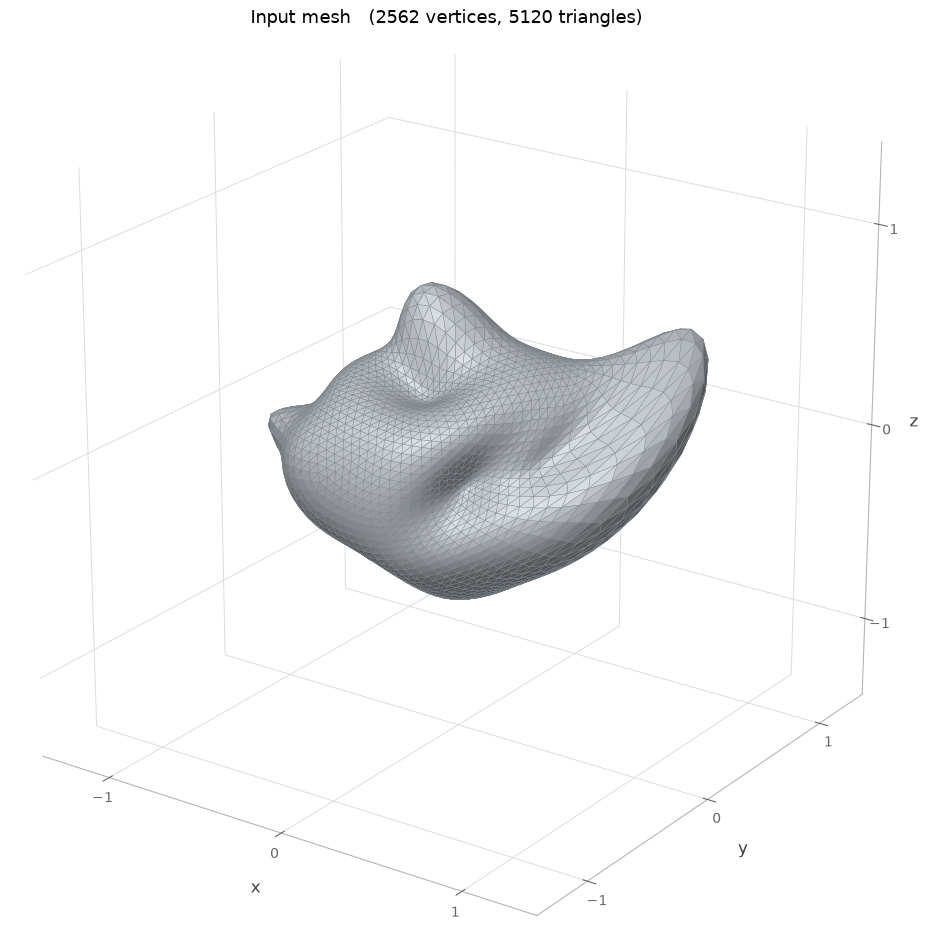


## Exercise 1: Inside or outside? Ray parity (11 points)

*Points: implementation and passing tests 10, Figure 1 1.*

The surface of a closed (watertight) mesh separates space into inside and outside. Shoot a ray $\mathbf o + t\,\mathbf d$, $t>0$, from the query point $\mathbf o$ in a fixed direction $\mathbf d$ and count how many triangles it crosses. The count is **odd if $\mathbf o$ is inside and even if it is outside**: every time the ray crosses the surface it switches between inside and outside, and it ends up outside. This is *ray parity*.

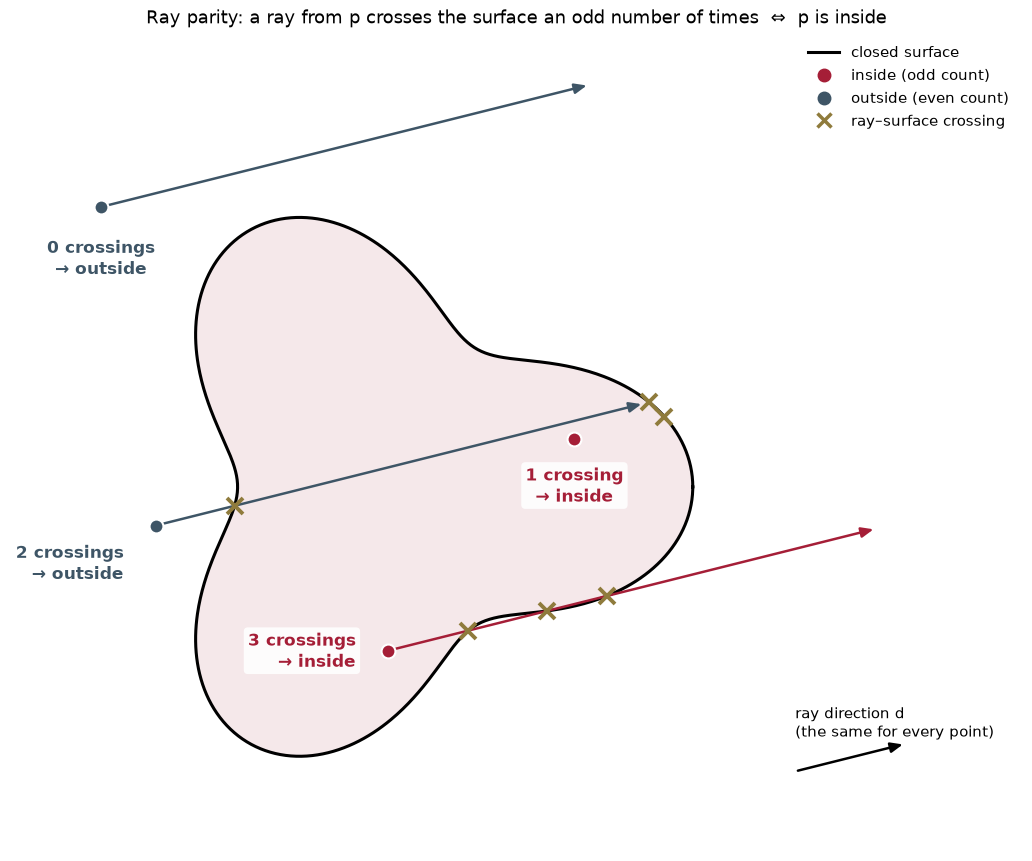

To count crossings you need a ray–triangle intersection test. The standard one is **Möller–Trumbore**. Write a point of the triangle $(\mathbf A,\mathbf B,\mathbf C)$ in barycentric form and equate it with the ray:

$$\mathbf o + t\,\mathbf d = \mathbf A + u\,(\mathbf B-\mathbf A) + v\,(\mathbf C-\mathbf A).$$

With $\mathbf E_1 = \mathbf B-\mathbf A$, $\mathbf E_2 = \mathbf C-\mathbf A$, $\mathbf T = \mathbf o - \mathbf A$, $\mathbf P = \mathbf d\times\mathbf E_2$, $\mathbf Q = \mathbf T\times\mathbf E_1$ this is a $3\times3$ linear system whose Cramer's-rule solution is

$$\begin{pmatrix} t\\u\\v \end{pmatrix} = \frac{1}{\mathbf P\cdot\mathbf E_1}\begin{pmatrix} \mathbf Q\cdot\mathbf E_2\\ \mathbf P\cdot\mathbf T\\ \mathbf Q\cdot\mathbf d \end{pmatrix}.$$

The ray hits the triangle iff $u \ge 0$, $v \ge 0$, $u+v \le 1$ and $t > 0$ (numerically: $t > \varepsilon$ with a tiny $\varepsilon$, so that a point lying exactly on a triangle is not counted as a hit). If the determinant $\mathbf P\cdot\mathbf E_1$ is (numerically) zero, the ray is parallel to the triangle plane and there is no hit.

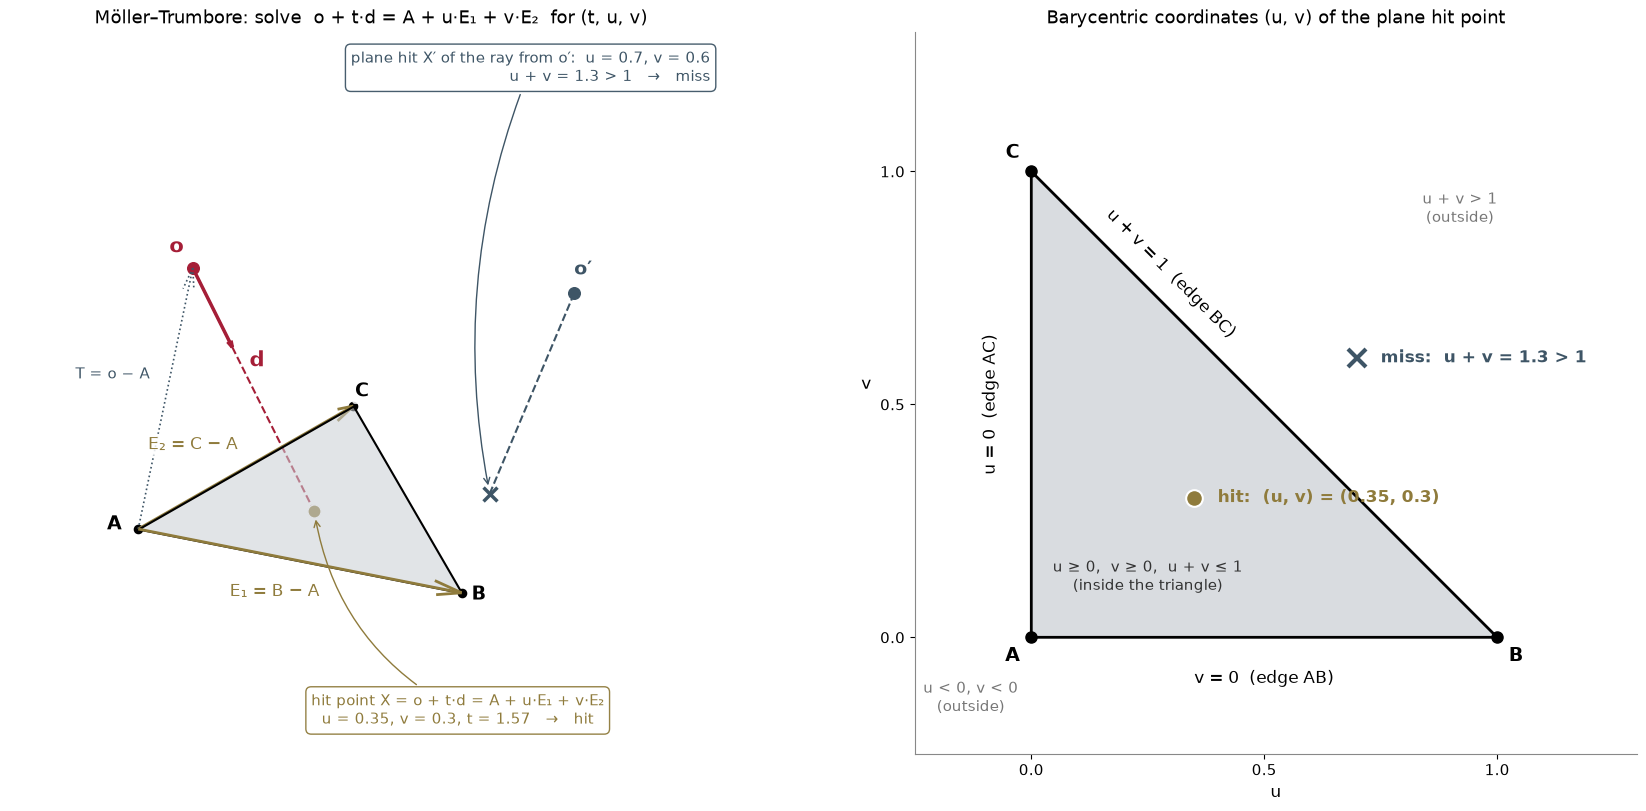

Left: the ray from $\mathbf o$ hits the triangle at $\mathbf X = \mathbf o + t\,\mathbf d$, which in the triangle's own coordinates is $\mathbf A + u\,\mathbf E_1 + v\,\mathbf E_2$. The ray from $\mathbf o'$ reaches the triangle's plane at a point with $u+v>1$, outside the triangle, so it is a miss. Right: the same two points in the $(u,v)$ plane, where the triangle is exactly the region $u\ge0,\ v\ge0,\ u+v\le1$.

**What you have to do**, in the cell below:

1. Implement `ray_triangle_hits(P, d, A, B, C)`: for `n` ray origins `P` (all sharing one direction `d`) and `m` triangles given by vertex arrays `A, B, C`, return a boolean `(n, m)` array of hits. Vectorise with broadcasting: do **not** loop over points or triangles in Python.
2. Implement `is_inside(P, V, F)`: ray parity with the provided direction `RAY_DIR`. Process points in chunks (`chunk=256`) so the `(n, m, 3)` intermediates fit in memory.
Then run the two cells after it: the tests must pass, and the second one draws **Figure 1**.

In [ ]:
#### START OF YOUR SOLUTION ####
def ray_triangle_hits(P, d, A, B, C, eps=1e-10):
    '''Möller–Trumbore hit test of n rays (one shared direction) against m triangles.

    Inputs
        P      : np.ndarray, float64, shape (n, 3)   ray origins (the query points)
        d      : np.ndarray, float64, shape (3,)     ray direction, unit length, shared by all rays
        A, B, C: np.ndarray, float64, shape (m, 3)   the three vertices of each of the m triangles
        eps    : float                               tolerance: |det| <= eps means parallel (no hit); a hit needs t > eps
    Output
        hit    : np.ndarray, bool, shape (n, m)      hit[i, j] is True iff ray i hits triangle j
    '''
    # Step 1: edge vectors of every triangle, E1 = B - A and E2 = C - A                -> shape (m,3)
    # Step 2: P = d x E2 with np.cross; d has shape (3,), so broadcast it to (1,3)       -> (m,3)
    # Step 3: determinant det = E1 . P, one number per triangle (np.einsum('mj,mj->m'))  -> (m,)
    # Step 4: validity: |det| <= eps means the ray is parallel to the triangle plane -> no hit.
    #         Build inv_det = 1/det only where valid (np.where) so you never divide by zero.
    # Step 5: T = o - A for EVERY (point, triangle) pair: P[:, None, :] - A[None]        -> (n,m,3)
    #         (this is the big intermediate; it is why is_inside works in chunks)
    # Step 6: u = (T . P) * inv_det  (np.einsum('nmj,mj->nm'))                            -> (n,m)
    # Step 7: Q = T x E1 with np.cross (broadcasts E1 to (1,m,3))                        -> (n,m,3)
    # Step 8: v = (Q . d) * inv_det  and  t = (Q . E2) * inv_det                           -> (n,m) each
    # Step 9: a hit needs ALL of: valid triangle, u >= 0, v >= 0, u + v <= 1 (inside the triangle),
    #         and t > eps (in front of the ray origin; t <= 0 would be behind it). Combine with &.
    # YOUR CODE HERE
    raise NotImplementedError()


def is_inside(P, V, F, chunk=256):
    '''Inside/outside test by ray parity along the fixed direction RAY_DIR.

    Inputs
        P     : np.ndarray, float64, shape (n, 3)    query points
        V     : np.ndarray, float64, shape (n_v, 3)  mesh vertex positions
        F     : np.ndarray, int64,   shape (n_f, 3)  mesh triangles as vertex indices into V
        chunk : int                                  number of query points processed per iteration
    Output
        inside: np.ndarray, bool, shape (n,)         inside[i] is True iff P[i] is inside the closed mesh
    '''
    # Step 1: gather the triangle vertex arrays A, B, C (each (m,3)) from V and F: A = V[F[:, 0]] etc.
    # Step 2: allocate the boolean result (n,)
    # Step 3: loop over chunks of `chunk` points (the only Python loop allowed): for each chunk
    #         call ray_triangle_hits with RAY_DIR, count the hits per point with .sum(1),
    #         and a point is inside iff that count is odd (count % 2 == 1).
    # YOUR CODE HERE
    raise NotImplementedError()
#### END YOUR SOLUTION ####


In [ ]:
# single triangle
A1, B1, C1 = np.array([[0., 0., 0.]]), np.array([[1., 0., 0.]]), np.array([[0., 1., 0.]])
hits = ray_triangle_hits(np.array([[0.2, 0.2, -1.0], [0.8, 0.8, -1.0], [0.2, 0.2, 1.0]]), np.array([0., 0., 1.]), A1, B1, C1)
assert isinstance(hits, np.ndarray) and hits.dtype == bool and hits.shape == (3, 1), f'expected bool array (3, 1), got {type(hits)} {getattr(hits, "dtype", None)} {getattr(hits, "shape", None)}'
assert hits[:, 0].tolist() == [True, False, False], hits   # inside tri / outside tri / behind the ray
# sphere: ground truth is |p| < 1
rng = np.random.default_rng(1); P_test = rng.uniform(-1.4, 1.4, (400, 3))
t0 = time.time(); ins = is_inside(P_test, V_sph, F_sph); dt = time.time() - t0
assert isinstance(ins, np.ndarray) and ins.dtype == bool and ins.shape == (400,), f'expected bool array (400,), got {type(ins)} {getattr(ins, "dtype", None)} {getattr(ins, "shape", None)}'
r = np.linalg.norm(P_test, axis=1); far = np.abs(r - 1.0) > 0.01   # ignore points within the icosphere's faceting error of the surface
err = (ins[far] != (r[far] < 1.0)).sum()
print(f'sphere test: {err} wrong out of {far.sum()}  ({dt:.2f} s)')
assert err == 0
# blob: the answer must not depend on the ray direction (checked with a second, different direction)
ins = is_inside(P_test, V, F)
A_, B_, C_ = V[F[:, 0]], V[F[:, 1]], V[F[:, 2]]
d2 = np.array([-0.62, 0.71, -0.33]); d2 /= np.linalg.norm(d2)
ins_d2 = np.concatenate([ray_triangle_hits(P_test[s:s + 256], d2, A_, B_, C_).sum(1) % 2 == 1 for s in range(0, len(P_test), 256)])
print(f'blob: disagreement between the two ray directions: {(ins != ins_d2).sum()},  inside fraction {ins.mean():.3f}')
assert (ins != ins_d2).sum() <= 2
print('Exercise 1 tests passed')


In [ ]:
rng = np.random.default_rng(2024)
P_fig1 = rng.uniform(-1.2, 1.2, (1500, 3))
inside_fig1 = is_inside(P_fig1, V, F)
fig_inside_points(P_fig1, inside_fig1, V, F)


### Expected result

These values do not depend on randomness, so your result should match. Only the timings in seconds depend on your machine. The points in Figure 1 are drawn with a fixed seed, so the figure should match too. Small differences in the framing and the fonts can come from the `matplotlib` version.

```text
sphere test: 0 wrong out of 396  (0.14 s)
blob: disagreement between the two ray directions: 0,  inside fraction 0.070
Exercise 1 tests passed
```

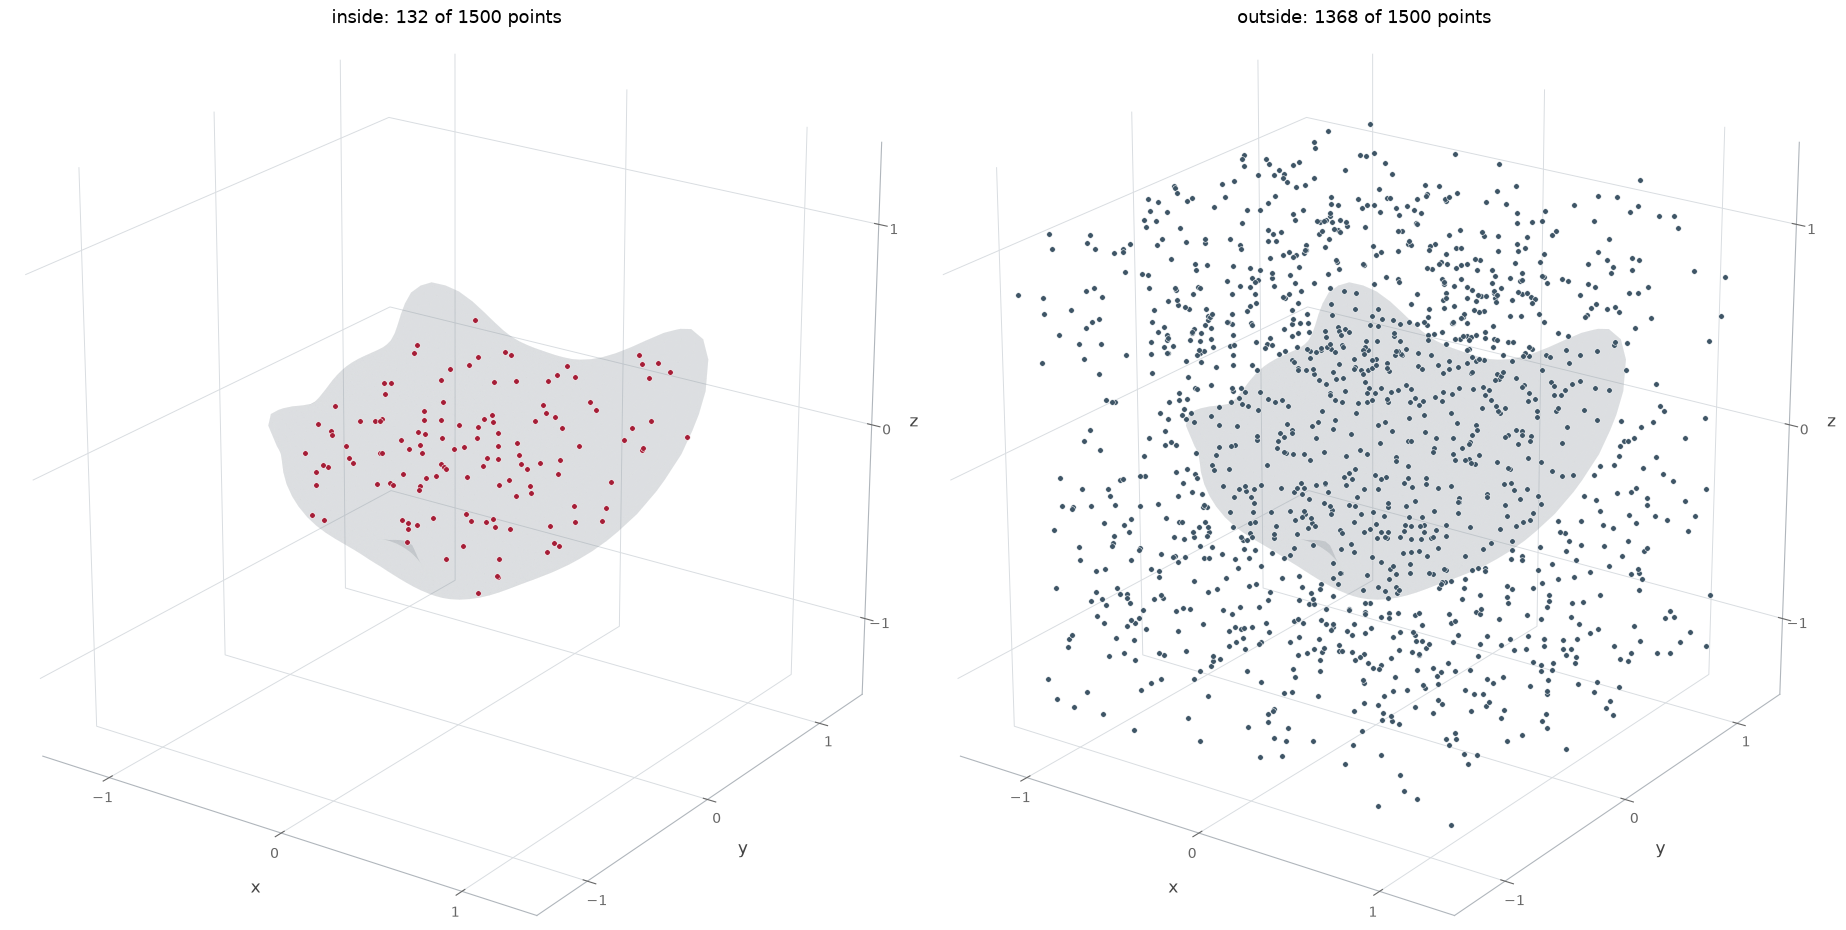


### Shortcomings of ray parity (not graded)

Your implementation works on our mesh, but it is worth knowing where the method breaks and what people use instead.

* **Degenerate hits.** If the ray passes exactly through an edge or a vertex it is counted once per triangle that shares it, and the parity flips; if it is coplanar with a triangle the test is undefined. Such directions form a set of measure zero, so an oblique direction like `RAY_DIR` almost never meets them, but "almost never" becomes "sometimes" on very large point sets or on meshes aligned with the grid. The standard fix is to shoot a few *random* rays and take a **majority vote** over their parities.

* **Only for watertight meshes.** With a hole in the mesh, rays leaving through the hole miss a crossing, so the answer depends on the direction and points near the hole are classified inconsistently. Scanned and reconstructed human meshes often have exactly such holes (under the arms, at the feet). Mesh orientation does not matter for parity, but an internal cavity (a surface inside a surface) counts as outside, which is usually what one wants.

* **Cost.** Every query tests all $m$ triangles, $O(m)$ per point. A bounding volume hierarchy over the triangles brings this to about $O(\log m)$ by skipping whole groups of triangles the ray cannot hit.

* **Alternatives.** The *generalised winding number* (Jacobson et al. 2013) sums the signed solid angles of all triangles seen from $\mathbf p$: it is exactly 1 inside and 0 outside a closed mesh, degrades gracefully with holes, and needs no rays. Another option, once you have the closest point from Exercise 2, is the sign of $(\mathbf p-\mathbf q)\cdot\mathbf n$ with $\mathbf n$ the normal at the closest point $\mathbf q$. Using the face normal fails when $\mathbf q$ lies on an edge or a vertex (the normal is ambiguous there, which happens a lot in concave regions); using the *angle-weighted pseudonormal* (Bærentzen & Aanæs 2005) makes it exact for closed meshes and comes for free with the distance computation.

## Exercise 2: Signed distance to the mesh (9 points)

*Points: distance functions and tests 6, SDF grid 3.*

The unsigned distance of $\mathbf p$ to a triangle mesh is the minimum over all triangles of the distance to the triangle, and the distance to a triangle is the distance to the **closest point on the triangle**. That closest point is either in the triangle's interior, on one of its three edges, or one of its three vertices. Working out which of these seven cases applies (Ericson, *Real-Time Collision Detection*, §5.1.5) is fiddly, so **don't worry, it is given**: the provided function `closest_point_on_triangles(P, A, B, C)` returns, for `n` points and `m` triangles, the `(n, m, 3)` array of closest points. You only need to call it.

With the closest points in hand, the distance of point $i$ to the mesh is
$$d_i = \min_j \|\mathbf p_i - \mathbf q_{ij}\|,$$
and the **sign** comes from Exercise 1: negative inside, positive outside, so $f_i = -d_i$ if `is_inside` says inside and $f_i = +d_i$ otherwise.

**What you have to do**:

1. Read the provided `closest_point_on_triangles` in the first cell below (you do not have to understand every line) and run its small test.
2. In the code cell after it, implement `unsigned_distance(P, V, F, chunk=256)`: minimum over triangles, chunked over points so the `(n, m, 3)` intermediate fits in memory. With `return_closest=True` it also returns the closest surface point of each query point.
3. Implement `signed_distance(P, V, F)` by combining `unsigned_distance` with `is_inside`.
4. Run the provided tests (sphere ground truth, **Figure 2a**). They must pass.
5. Evaluate the SDF on the `GRID_N³` grid and store it as `sdf_grid` of shape `(GRID_N, GRID_N, GRID_N)`. The cell saves it to `sdf_grid.npy`: submit this file together with the notebook.
6. Run the provided check of the eikonal property $\|\nabla f\| = 1$, with finite differences on the grid (**Figure 2b**).

In [ ]:
def closest_point_on_triangles(P, A, B, C):
    '''P: (n,3) points, A,B,C: (m,3) triangle vertices. Returns Q: (n,m,3), Q[i,j] = closest point on triangle j to point i.'''
    # Step 1: edge vectors ab, ac, bc (m,3) and the point-to-vertex vectors ap, bp, cp (n,m,3) via P[:, None, :] - A[None]
    ab, ac, bc = B - A, C - A, C - B
    ap = P[:, None, :] - A[None]; bp = P[:, None, :] - B[None]; cp = P[:, None, :] - C[None]
    # Step 2: the six dot products d1..d6 of the table, each (n,m)  (np.einsum('mj,nmj->nm', edge, vec))
    d1 = np.einsum('mj,nmj->nm', ab, ap); d2 = np.einsum('mj,nmj->nm', ac, ap)
    d3 = np.einsum('mj,nmj->nm', ab, bp); d4 = np.einsum('mj,nmj->nm', ac, bp)
    d5 = np.einsum('mj,nmj->nm', ab, cp); d6 = np.einsum('mj,nmj->nm', ac, cp)
    # Step 3: va, vb, vc (n,m)
    va = d3 * d6 - d5 * d4; vb = d5 * d2 - d1 * d6; vc = d1 * d4 - d3 * d2
    # Step 4: guard every division: replace a zero denominator by 1 with np.where (the result is overwritten anyway)
    safe = lambda x: np.where(x == 0, 1.0, x)
    # Step 5: start with the interior candidate Q = A + v*ab + w*ac for all pairs  (n,m,3)
    denom = safe(va + vb + vc); v = vb / denom; w = vc / denom
    Q = A[None] + v[..., None] * ab[None] + w[..., None] * ac[None]
    # Step 6: overwrite with the edge candidates, then with the vertex candidates, using np.where(mask[..., None], candidate, Q).
    #         Because later np.where calls overwrite earlier ones, apply the table from the BOTTOM up so its first rows win.
    m = (va <= 0) & (d4 - d3 >= 0) & (d5 - d6 >= 0)
    Q = np.where(m[..., None], B[None] + ((d4 - d3) / safe((d4 - d3) + (d5 - d6)))[..., None] * bc[None], Q)
    m = (vb <= 0) & (d2 >= 0) & (d6 <= 0)
    Q = np.where(m[..., None], A[None] + (d2 / safe(d2 - d6))[..., None] * ac[None], Q)
    m = (vc <= 0) & (d1 >= 0) & (d3 <= 0)
    Q = np.where(m[..., None], A[None] + (d1 / safe(d1 - d3))[..., None] * ab[None], Q)
    Q = np.where(((d6 >= 0) & (d5 <= d6))[..., None], np.broadcast_to(C[None], Q.shape), Q)
    Q = np.where(((d3 >= 0) & (d4 <= d3))[..., None], np.broadcast_to(B[None], Q.shape), Q)
    Q = np.where(((d1 <= 0) & (d2 <= 0))[..., None], np.broadcast_to(A[None], Q.shape), Q)
    return Q

# small test of the provided function: one triangle, points in different Voronoi regions (expected closest points by hand)
A1, B1, C1 = np.array([[0., 0., 0.]]), np.array([[2., 0., 0.]]), np.array([[0., 2., 0.]])
P1 = np.array([[0.5, 0.5, 3.0],    # above interior -> (0.5, 0.5, 0)
               [-1.0, -1.0, 0.0],  # beyond vertex A -> A
               [3.0, -1.0, 1.0],   # beyond vertex B -> B
               [1.0, -1.0, 0.0],   # beyond edge AB -> (1, 0, 0)
               [2.0, 2.0, 0.0]])   # beyond edge BC -> (1, 1, 0)
Q1 = closest_point_on_triangles(P1, A1, B1, C1)[:, 0]
expected = np.array([[0.5, 0.5, 0], [0, 0, 0], [2, 0, 0], [1, 0, 0], [1, 1, 0]], dtype=float)
assert np.allclose(Q1, expected), Q1
print('closest points on the test triangle:\n', Q1)


In [ ]:
#### START OF YOUR SOLUTION ####
def unsigned_distance(P, V, F, chunk=256, return_closest=False):
    '''Unsigned (always >= 0) distance from each query point to the mesh surface.

    Inputs
        P             : np.ndarray, float64, shape (n, 3)    query points
        V             : np.ndarray, float64, shape (n_v, 3)  mesh vertex positions
        F             : np.ndarray, int64,   shape (n_f, 3)  mesh triangles as vertex indices into V
        chunk         : int                                  number of query points processed per iteration
        return_closest: bool                                 if True, return the tuple (d, Q) instead of d alone
    Output
        d             : np.ndarray, float64, shape (n,)      d[i] = distance of P[i] to the nearest triangle
        Q (only if return_closest): np.ndarray, float64, shape (n, 3)   closest surface point of each P[i]; returned as (d, Q)
    '''
    # Step 1: triangle vertex arrays A, B, C from V and F
    # Step 2: allocate outputs d (n,) and the closest points Qbest (n,3)
    # Step 3: for each chunk of points: closest points Q (n_c,m,3), distances |Q - P| (n_c,m) with np.linalg.norm(axis=2),
    #         the index of the nearest triangle with argmin(1), then pick that distance and that point per row.
    # YOUR CODE HERE
    raise NotImplementedError()


def signed_distance(P, V, F, **kw):
    '''Signed distance: negative inside the mesh, positive outside, zero on the surface.

    Inputs
        P : np.ndarray, float64, shape (n, 3)      query points
        V : np.ndarray, float64, shape (n_v, 3)    mesh vertex positions
        F : np.ndarray, int64,   shape (n_f, 3)    mesh triangles
        kw: forwarded to unsigned_distance (e.g. chunk)
    Output
        f : np.ndarray, float64, shape (n,)        f[i] = -d[i] if P[i] is inside, +d[i] otherwise
    '''
    # unsigned distance from above, sign from Exercise 1: negative where is_inside is True (np.where)
    # YOUR CODE HERE
    raise NotImplementedError()
#### END YOUR SOLUTION ####


In [ ]:
# sphere ground truth: f = |p| - 1  (icosphere faceting error ~1e-3)
rng = np.random.default_rng(5); P_test = rng.uniform(-1.4, 1.4, (500, 3))
t0 = time.time(); f_test = signed_distance(P_test, V_sph, F_sph); dt = time.time() - t0
assert isinstance(f_test, np.ndarray) and f_test.dtype == np.float64 and f_test.shape == (500,), f'expected float64 array (500,), got {type(f_test)} {getattr(f_test, "dtype", None)} {getattr(f_test, "shape", None)}'
d_u, q_u = unsigned_distance(P_test[:10], V_sph, F_sph, return_closest=True)
assert d_u.shape == (10,) and q_u.shape == (10, 3) and (d_u >= 0).all(), 'unsigned_distance: expected d (10,) >= 0 and Q (10, 3)'
assert np.allclose(np.linalg.norm(q_u, axis=1), 1.0, atol=5e-3), 'closest points on the icosphere must lie on the unit sphere'
err = f_test - (np.linalg.norm(P_test, axis=1) - 1.0)
print(f'sphere: max |error| = {np.abs(err).max():.2e}  ({dt:.2f} s for 500 points)')
assert np.abs(err).max() < 5e-3
fig_hist(err, 'Figure 2a: SDF error on the icosphere (f − (|p|−1))', 'error', xlim=(-0.004, 0.004), vline=0)
print('Exercise 2 tests passed')


In [ ]:
# expected result: sdf_grid : np.ndarray, float64, shape (GRID_N, GRID_N, GRID_N)
# inputs available: axis_coords : float64 (GRID_N,)   P_grid : float64 (GRID_N**3, 3), in 'ij' order
axis_coords, P_grid = make_grid(GRID_N)
t0 = time.time()
# evaluate signed_distance on all grid points P_grid (GRID_N^3, 3) and reshape to (GRID_N, GRID_N, GRID_N);
# the 'ij' ordering of make_grid makes sdf_grid[i, j, k] the value at (axis_coords[i], axis_coords[j], axis_coords[k])
#### START OF YOUR SOLUTION ####
# Define: sdf_grid
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####
print(f'SDF on {GRID_N}^3 grid: {time.time() - t0:.1f} s,  min {sdf_grid.min():.3f}, max {sdf_grid.max():.3f}')
assert isinstance(sdf_grid, np.ndarray) and sdf_grid.shape == (GRID_N, GRID_N, GRID_N) and sdf_grid.dtype == np.float64, 'expected float64 array (GRID_N, GRID_N, GRID_N)'
np.save('sdf_grid.npy', sdf_grid)   # submit this file together with the notebook


In [ ]:
h = axis_coords[1] - axis_coords[0]
gx, gy, gz = np.gradient(sdf_grid, h)
grad_norm = np.sqrt(gx ** 2 + gy ** 2 + gz ** 2)
print(f'|grad f|: mean {grad_norm.mean():.4f}, 5th/95th percentile {np.percentile(grad_norm, 5):.4f} / {np.percentile(grad_norm, 95):.4f}')
fig_hist(grad_norm.ravel(), 'Figure 2b: |∇f| on the grid (central differences)', '|∇f|', xlim=(0.5, 1.5), vline=1.0)


### Expected result

These values do not depend on randomness, so your result should match. Only the timings in seconds depend on your machine. Both histograms should match, and all the `assert`s must pass. Small differences in the framing and the fonts can come from the `matplotlib` version.

```text
sphere: max |error| = 1.13e-03  (0.78 s for 500 points)
Exercise 2 tests passed
SDF on 32^3 grid: 50.1 s,  min -0.453, max 1.874
|grad f|: mean 0.9903, 5th/95th percentile 0.9658 / 1.0043
```

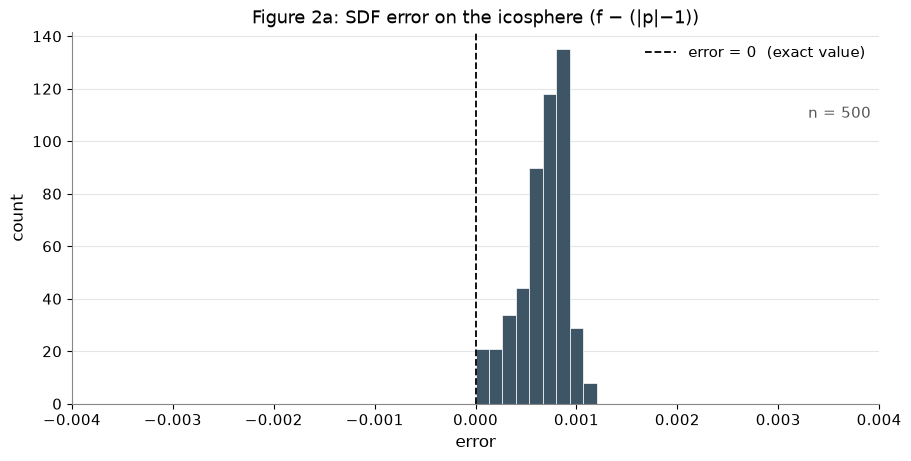

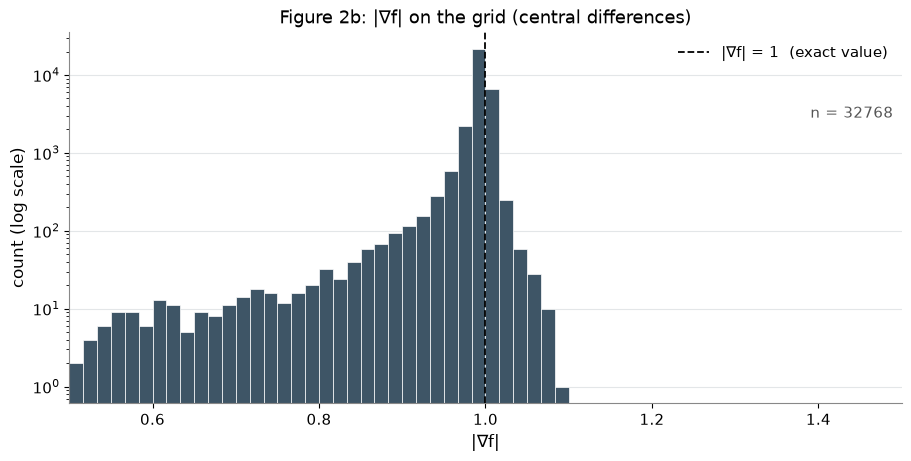


### Interesting facts about distance fields (not graded)

* **Where $\|\nabla f\| = 1$ fails.** Figure 2b shows values below 1. They occur in grid cells that straddle the **medial axis**, the set of points with two or more equidistant closest surface points (inside the shape it is the skeleton; outside it is, for example, the bisector between two bumps). There $f$ has a kink and is not differentiable: the central difference averages two gradients pointing in different directions, and the average is shorter than 1. Values slightly above 1 are finite-difference noise from the sign change at the surface and from the icosphere's faceting.

* **The one-step projection has the same blind spot.** The lecture demo claims $\mathbf q = \mathbf p - f(\mathbf p)\nabla f(\mathbf p)$ lands exactly on the surface. That is true wherever $f$ is differentiable. On the medial axis the gradient is undefined; whichever one-sided gradient you pick still lands on *a* closest point, but a finite-difference gradient there has norm below 1 and the step undershoots. Networks that learn an SDF are usually regularised with an **eikonal loss** $(\|\nabla f\| - 1)^2$ for the same reason: it forces the learned field to behave like a distance.

* **Brute force is the slow part.** Your implementation compares every point with every triangle: $32^3 \times 5120 \approx 1.7\cdot10^8$ point–triangle pairs for the grid. A **bounding volume hierarchy** (an AABB tree over the triangles) or a k-d tree over triangle bounding boxes prunes most of them: if a node's box is farther away than the best distance found so far, no triangle inside it can be closer and the whole subtree is skipped, giving roughly $O(\log m)$ triangles per query. Libraries such as `trimesh`, `libigl` and `pysdf` do exactly this, which is why they answer the same query in milliseconds.

* **Sign from the closest point.** Once you have $\mathbf q$ you do not need rays at all: the sign of $(\mathbf p - \mathbf q)\cdot\mathbf n(\mathbf q)$ tells inside from outside, provided $\mathbf n$ is the angle-weighted pseudonormal when $\mathbf q$ lies on an edge or a vertex (see the end of Exercise 1). This is how most production SDF code computes the sign.

* **Narrow bands.** Most applications only need $f$ near the surface. Storing or computing it only within a band $|f| < \beta$, as in the lecture demo *Level sets on a grid*, cuts the cost by the ratio of the band volume to the domain volume, and the truncated field (a TSDF) is what depth-fusion systems such as KinectFusion accumulate.

## Exercise 3: Level sets (10 points)

*Points: iso-surface extraction 4, Figures 3a, 3b and 3c 2 each.*

A sampled SDF implicitly describes a whole family of surfaces: the level set $\{\mathbf p : f(\mathbf p) = \tau\}$ for every iso-value $\tau$. $\tau = 0$ is the original surface, $\tau>0$ is an offset (dilated) surface, $\tau<0$ an eroded one. In 2D the lecture demo drew these as contour lines; in 3D we extract them with **marching cubes** (`skimage.measure.marching_cubes`), the 3D analogue of the marching squares you saw in the demo.

**What you have to do**, in the three cells below:

1. Implement `extract_isosurface(sdf_grid, axis_coords, level)` that returns `(Vi, Fi)` of the level set in **world coordinates**. Read the documentation of `skimage.measure.marching_cubes`: it returns vertices in index space scaled by `spacing`, so you must add the grid origin, and the grid must be sampled in `'ij'` order (which `make_grid` does).
2. **Figure 3a**: the first cell then draws planar slices through the SDF with contours at `LEVELS`. This plot is provided.
3. **Figure 3b**: in the second cell, build `iso_meshes`, with one iso-surface for each level in `ISO_LEVELS`.
4. **Figure 3c**: in the third cell, build `sweep_meshes`, the zero level set extracted from grids of resolution `SWEEP_N` = 12, 20, 32. Compute the SDF again at the lower resolutions with your own `signed_distance`.

Do not change the plotting helpers, levels, colours or camera: we grade by comparing your figures with the reference figures.

In [ ]:
#### START OF YOUR SOLUTION ####
def extract_isosurface(sdf_grid, axis_coords, level):
    '''Triangle mesh of the level set {f = level} by marching cubes, in world coordinates.

    Inputs
        sdf_grid   : np.ndarray, float64, shape (n, n, n)   sampled SDF, sdf_grid[i, j, k] = f(axis_coords[i], axis_coords[j], axis_coords[k])
        axis_coords: np.ndarray, float64, shape (n,)        the (uniform) grid coordinates along each axis
        level      : float                                  the iso-value
    Output
        Vi : np.ndarray, float (float32 or float64), shape (k, 3)   vertex positions in world coordinates
        Fi : np.ndarray, int,   shape (l, 3)                        triangles as vertex indices into Vi
    '''
    # Step 1: grid spacing h from axis_coords (uniform grid)
    # Step 2: measure.marching_cubes(volume, level=..., spacing=(h, h, h)) returns (verts, faces, normals, values);
    #         verts are in index*spacing units, i.e. relative to the grid corner, not world coordinates
    # Step 3: shift by the grid origin (axis_coords[0] on every axis) to get world coordinates
    # YOUR CODE HERE
    raise NotImplementedError()
#### END YOUR SOLUTION ####

# Figure 3a: slices
Vi0, Fi0 = extract_isosurface(sdf_grid, axis_coords, 0.0)
assert Vi0.ndim == 2 and Vi0.shape[1] == 3 and Fi0.ndim == 2 and Fi0.shape[1] == 3 and np.issubdtype(Fi0.dtype, np.integer), 'expected Vi (k, 3) float and Fi (l, 3) int'
assert np.abs(Vi0).max() <= DOMAIN + 1e-6 and np.abs(Vi0).max() > 0.5, 'vertices must be in world coordinates (did you add the grid origin?)'
fig_slices(sdf_grid, axis_coords)


In [ ]:
# Figure 3b: iso-surfaces at ISO_LEVELS
# expected result: iso_meshes : list of len(ISO_LEVELS) = 4 tuples (Vi, Fi), Vi float (k, 3), Fi int (l, 3), one per level in ISO_LEVELS
# iso_meshes: a list with one (Vi, Fi) per level in ISO_LEVELS, from extract_isosurface on sdf_grid
#### START OF YOUR SOLUTION ####
# Define: iso_meshes
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

fig_isosurfaces(iso_meshes)


In [ ]:
# Figure 3c: zero level set from grids of resolution SWEEP_N (recompute the SDF at each resolution)
# expected result: sweep_meshes : list of len(SWEEP_N) = 3 tuples (Vi, Fi), Vi float (k, 3), Fi int (l, 3), one per n in SWEEP_N
t0 = time.time()
# sweep_meshes: one (Vi, Fi) per n in SWEEP_N. For each n: make_grid(n), signed_distance on its points,
# reshape to (n, n, n), extract the level 0 iso-surface. You may reuse sdf_grid for n == GRID_N.
#### START OF YOUR SOLUTION ####
# Define: sweep_meshes
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

print(f'resolution sweep: {time.time() - t0:.1f} s')
fig_resolution(sweep_meshes)


### Expected result

Nothing here is random, so the figures and the triangle counts in their titles should match. Only the timing in seconds depends on your machine, and small differences in the framing and the fonts can come from the `matplotlib` version.

```text
resolution sweep: 14.8 s
```

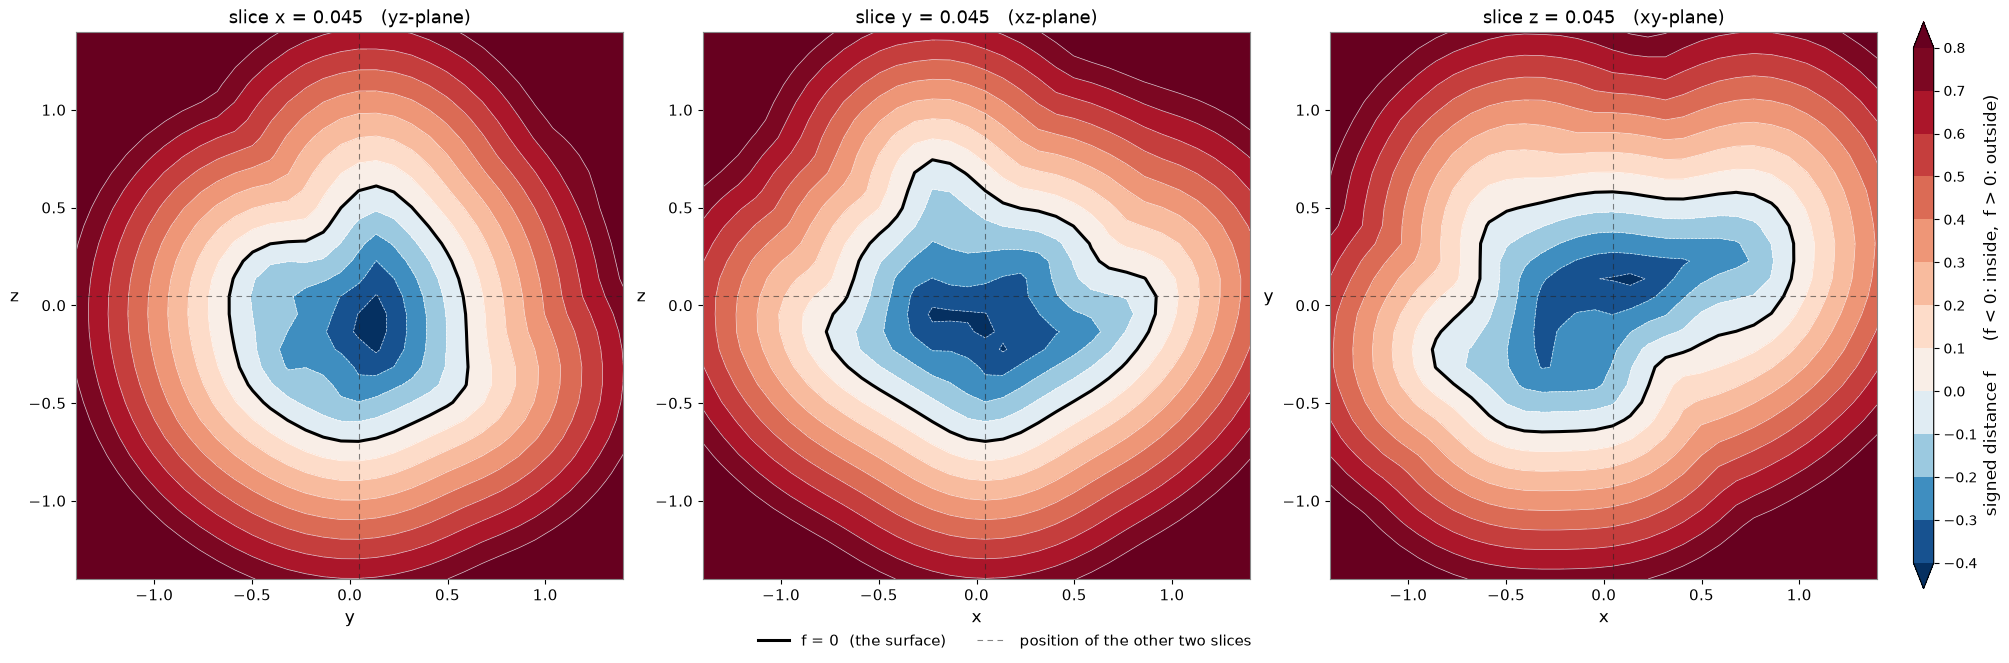

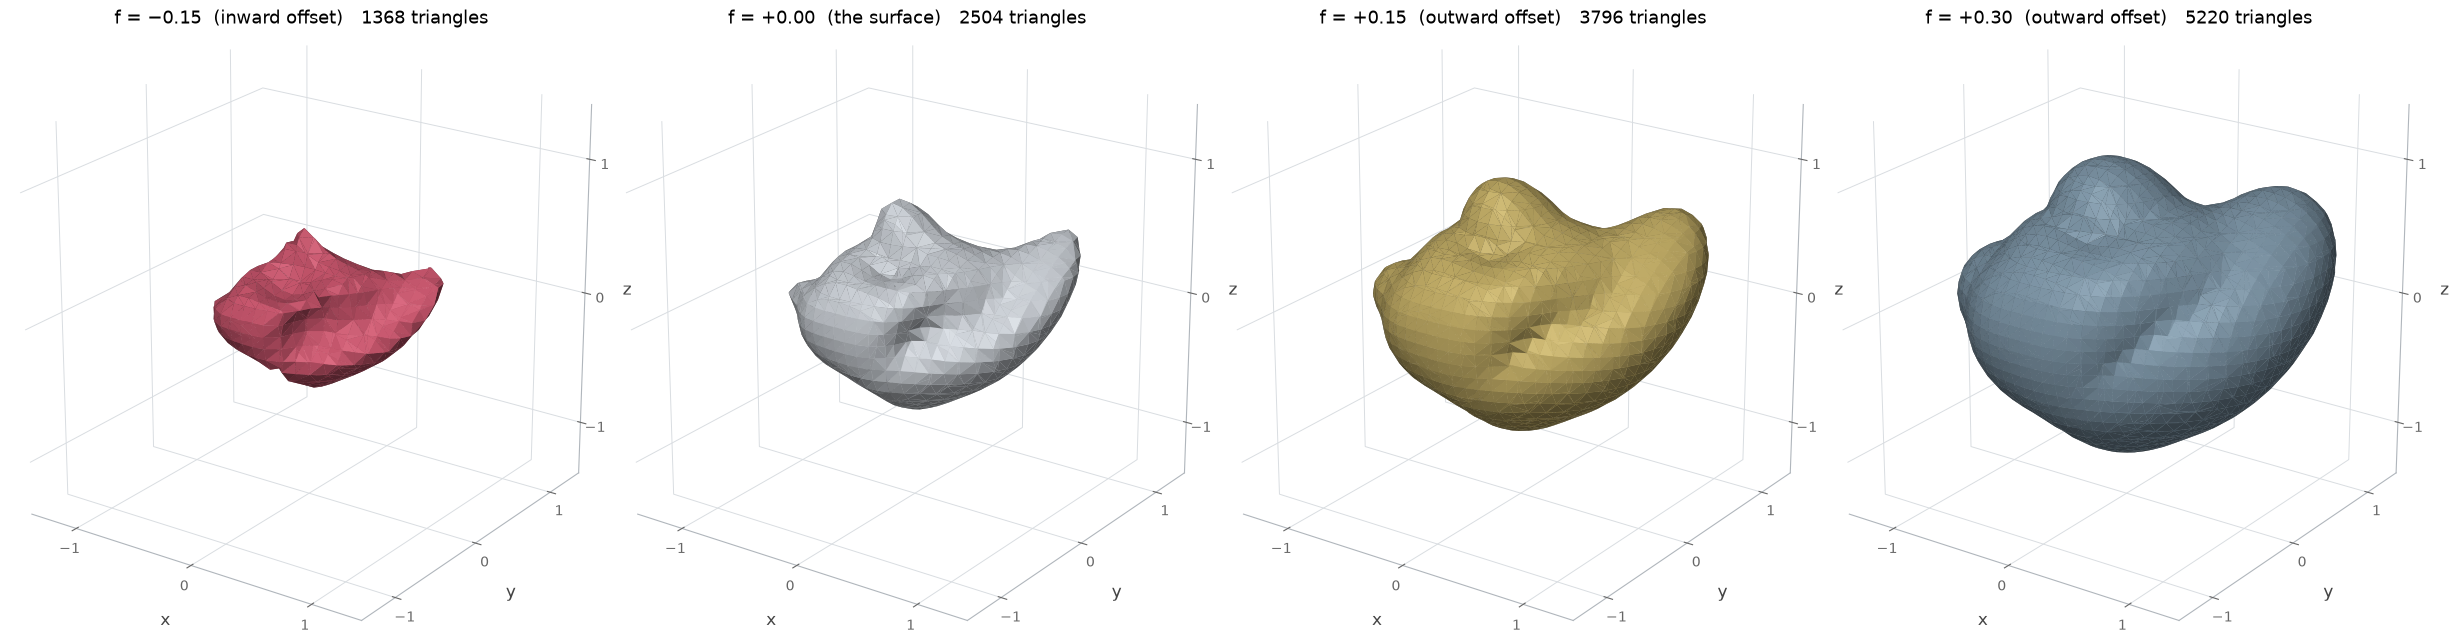

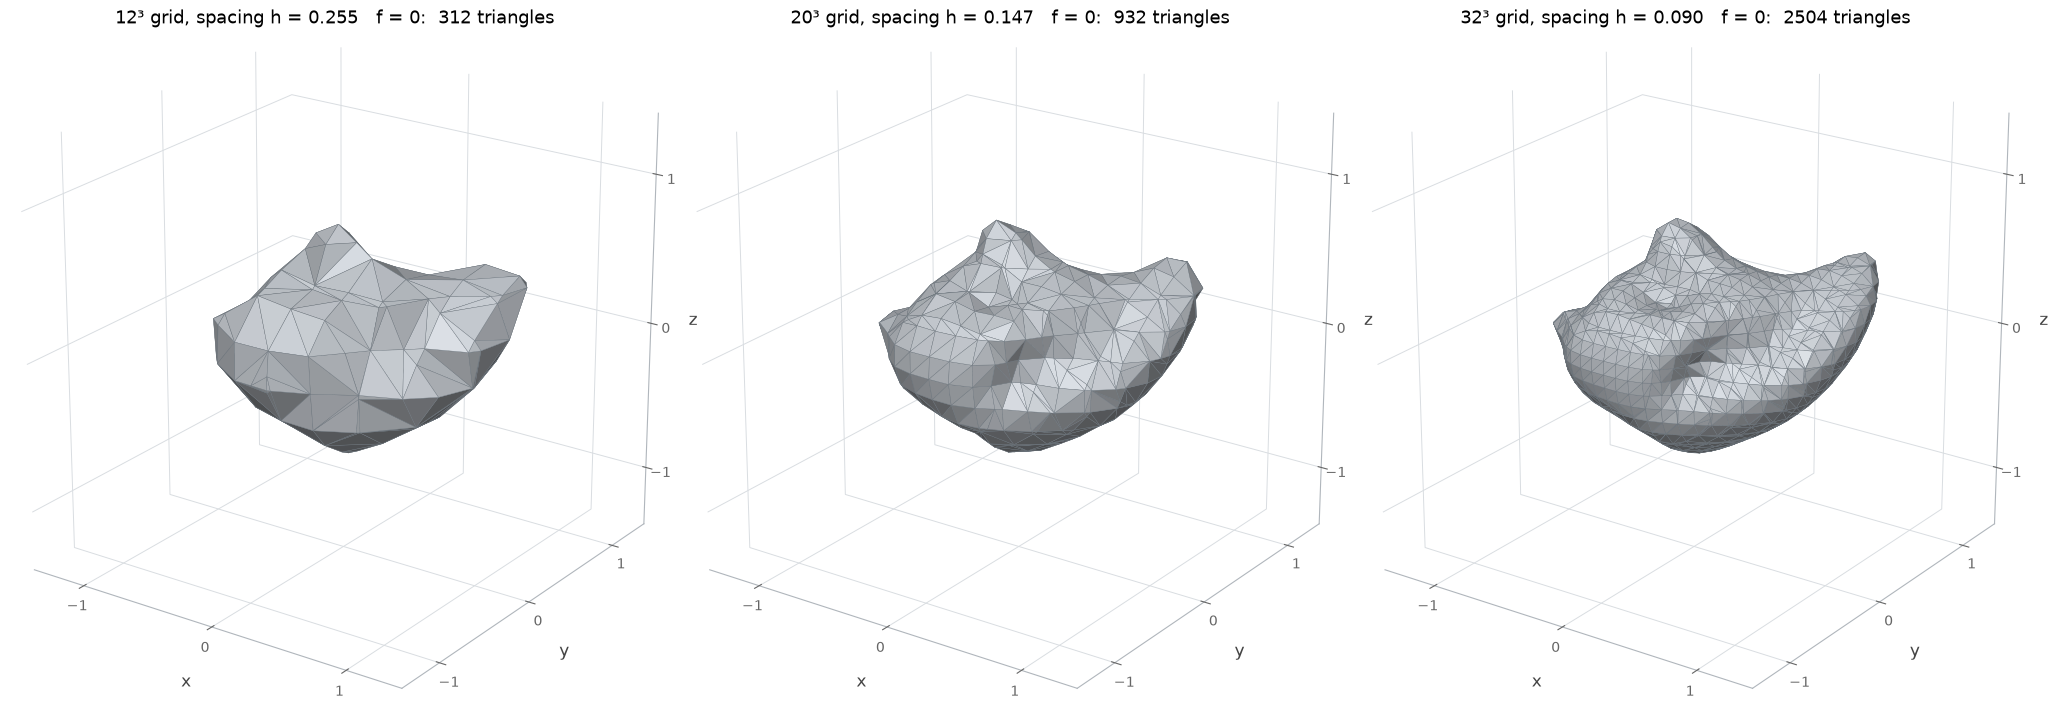


### Interesting facts about level sets (not graded)

* **Offsets fill dents.** Compare the $f=0$ and $f=+0.30$ surfaces in Figure 3b: the concave regions have disappeared. An offset surface is the boundary of the Minkowski sum of the shape with a ball of radius $\tau$, so every concavity whose radius of curvature is below $\tau$ is bridged by the ball and vanishes, while convex parts are simply pushed outward and get rounder. Dilation can only remove concave detail, never add any. This is also why $f=\tau$ followed by $f=-\tau$ (a *closing* in morphology) smooths a shape.

* **Grid spacing sets the smallest feature.** In Figure 3c the small bumps and the narrow dents between them vanish first, then the silhouette becomes blocky. A feature must be sampled by a few grid points to be reconstructed, so with spacing $h$ the smallest reliably represented feature is about $2h$ (the Nyquist limit); features thinner than $h$ can disappear entirely or produce spurious blobs, exactly the aliasing you saw in the lecture demo *Level sets on a grid* when the resolution slider was lowered. At $12^3$ the spacing is $0.25$, comparable to the bump width, so the bumps are mostly gone; at $32^3$ ($h\approx0.09$) they are resolved. Learned implicit models of humans face the same trade-off: fingers and facial features need a fine grid (or an adaptive one) at extraction time.

* **Triangle count tracks area, not detail.** Marching cubes emits one to four triangles per grid cell the level set crosses, so the count in the titles of Figure 3b is roughly surface area divided by $h^2$. Dilating increases the area (and the count) even though the surface gets smoother and carries less information; eroding does the opposite; halving $h$ quadruples the count for the same surface. At $f=+0.5$ the offset surface would leave our domain $[-1.4,1.4]^3$ and marching cubes would clip it against the grid boundary, returning an open surface with holes at the box faces.

* **Why distance, and not just occupancy?** An occupancy grid (inside = 1, outside = 0) also gives the $f=0$ surface, but only a signed distance gives the *whole family* of level sets, the normals via $\nabla f$, and the closest-point projection $\mathbf q=\mathbf p-f\,\nabla f$ from the lecture demo. For learning, a distance target is smooth and informative everywhere in space, whereas occupancy is a step function that is uninformative away from the surface.

# Part 2: Procrustes Analysis (26 points)

**Goal**: given two point clouds with known correspondences, find the scale, rotation and translation that align them. This is the simplest form of shape registration, and it shows why registration depends on correspondences.

You will do four things:

- Exercise 4: transform a point cloud with a scale, a rotation and a translation.
- Exercise 5: implement Procrustes analysis and recover that transformation.
- Exercise 6: recover the transformation from noisy data.
- Questions 1 to 3: find out where the method stops working.

This part does not use anything from Part 1.


**Run this cell. No code needed.**

In [ ]:
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np

POINT_CLOUD_URL = 'https://raw.githubusercontent.com/erodola/NumMeth-s2-2022/main/esercizi/ex6/point_cloud.txt'
if not os.path.exists('point_cloud.txt'):
    urllib.request.urlretrieve(POINT_CLOUD_URL, 'point_cloud.txt')

# A has shape (N, 2): each row is a point
A = np.loadtxt('point_cloud.txt').T
print('A:', A.shape)


def plot_clouds(X, Y, label_x='X', label_y='Y', title=None):
    plt.figure(figsize=(6, 5))
    plt.scatter(X[:, 0], X[:, 1], color='tab:blue', label=label_x)
    plt.scatter(Y[:, 0], Y[:, 1], color='tab:red', marker='.', label=label_y)
    plt.axis('equal')
    plt.legend()
    if title:
        plt.title(title)
    plt.show()


def rmse(X, Y):
    """Root mean squared distance between corresponding points."""
    return np.sqrt(np.mean(np.sum((X - Y) ** 2, axis=1)))

## Exercise 4: Apply a similarity transformation (3 points)

A similarity transformation maps each point $x$ to

$$T(x) = s R x + t$$

where $s > 0$ is a scale, $R$ a rotation matrix and $t$ a translation. It scales and rotates around the origin, and translates last.

Our points are stored as rows, so for a matrix $X$ of shape $(N, d)$ this is written `s * X @ R.T + t`.

**What you have to do**, in the cell below:

1. Write `rotation_matrix(degrees)`. It takes an angle in degrees and returns the $2 \times 2$ matrix that rotates points counter-clockwise by that angle.
2. Write `apply_similarity(X, s, R, t)`. It takes points of shape $(N, d)$ and returns the transformed points, with the same shape.
3. Define `s_true = 1.5`, `R_true` (a rotation of $30$ degrees) and `t_true = (1, 0.5)`.
4. Compute `B` by applying this transformation to `A`.

The plot at the end of the cell should show `B` as a larger, tilted copy of `A`, moved up and to the right.

In [ ]:
#### START OF YOUR SOLUTION ####
def rotation_matrix(degrees):
    """Return the 2D rotation matrix for an angle in degrees."""
    # YOUR CODE HERE
    raise NotImplementedError()


def apply_similarity(X, s, R, t):
    """Apply T(x) = s R x + t to the rows of X."""
    # YOUR CODE HERE
    raise NotImplementedError()


# Define: s_true, R_true, t_true, B
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

plot_clouds(A, B, 'A', 'B', 'A and its transformed copy B')

### Expected result

The plot should match, since nothing here is random.

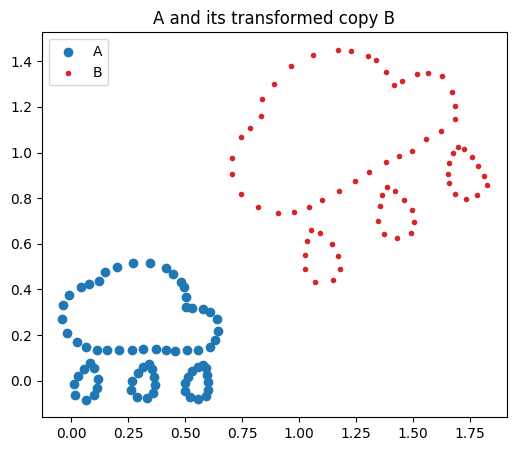

## Exercise 5: Implement Procrustes analysis (10 points)

Given corresponding points $x_i$ and $y_i$, we look for

$$\min_{s, R, t} \sum_{i=1}^{N} \| s R x_i + t - y_i \|^2 .$$

This problem has a closed-form solution:

1. Compute the centroids $\bar{x}$ and $\bar{y}$, and the centered points $\tilde{x}_i = x_i - \bar{x}$ and $\tilde{y}_i = y_i - \bar{y}$.
2. Compute the cross-covariance matrix $H = \sum_i \tilde{y}_i \tilde{x}_i^T$ and its SVD $H = U \Sigma V^T$.
3. The rotation is $R = U D V^T$ with $D = \mathrm{diag}(1, \dots, 1, \det(U V^T))$. Without $D$, the result $U V^T$ can be a reflection, which is not a rotation.
4. The scale is $s = \mathrm{tr}(\Sigma D) \, / \sum_i \|\tilde{x}_i\|^2$.
5. The translation is $t = \bar{y} - s R \bar{x}$.

**What you have to do**, in the cell below:

1. Write `procrustes(X, Y, allow_reflection=False)`, following the five steps above. `X` and `Y` have shape $(N, d)$, and `Y[i]` corresponds to `X[i]`. The function returns `s, R, t`. Do not assume $d = 2$: the same function must also work in 3D.
2. If `allow_reflection` is `True`, skip the correction by using $D = I$. You will need this in Question 2.
3. Call `procrustes(A, B)` and store the result in `s_rec, R_rec, t_rec`.
4. Compute `B_rec` by applying the recovered transformation to `A`.

The rest of the cell prints your results and compares them with the true values. If an `assert` fails, your implementation is wrong: all of them must pass.

In [ ]:
#### START OF YOUR SOLUTION ####
def procrustes(X, Y, allow_reflection=False):
    """
    Find s, R, t minimizing the distance between s R x_i + t and y_i.
    :param X: (N, d) source points
    :param Y: (N, d) target points, where Y[i] corresponds to X[i]
    :param allow_reflection: if True, R may have determinant -1
    :return: s, R, t
    """
    # YOUR CODE HERE
    raise NotImplementedError()


# Define: s_rec, R_rec, t_rec, B_rec
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

print('scale      :', s_rec, '(true:', s_true, ')')
print('rotation   :\n', R_rec)
print('translation:', t_rec, '(true:', t_true, ')')
print('RMSE       :', rmse(B_rec, B))

assert np.isclose(s_rec, s_true)
assert np.allclose(R_rec, R_true)
assert np.allclose(t_rec, t_true)
assert rmse(B_rec, B) < 1e-10

plot_clouds(B, B_rec, 'B', 'T(A)', 'Recovered transformation')

### Expected result

These values do not depend on randomness, so your result should match, apart from tiny numerical differences such as the digits of values close to $10^{-16}$.

```text
scale      : 1.5 (true: 1.5 )
rotation   :
 [[ 0.8660254 -0.5      ]
 [ 0.5        0.8660254]]
translation: [1.  0.5] (true: [1.  0.5] )
RMSE       : 5.714067332473954e-16
```

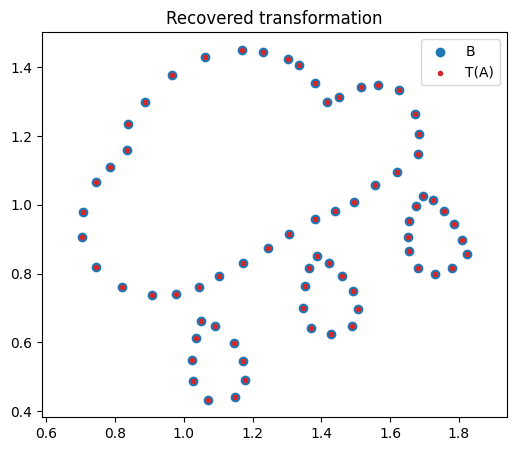

## Exercise 6: Noise (4 points: 2 code, 2 written)

Real data is never exact. Add independent Gaussian noise to every coordinate of the target:

$$B_{noisy} = s R A + t + N, \qquad N_{ij} \sim \mathcal{N}(0, \sigma^2)$$

**What you have to do**, in the cell below:

1. Write `rotation_angle(R)`, which returns the angle of a 2D rotation matrix in degrees. Hint: `np.arctan2`.
2. Write `noise_experiment(sigma, rng)`, which must:
    - add the noise to the points: compute $s R A + t$ with the true values of Exercise 4, then add a matrix of noise of the same shape as `A`, drawn with `rng.normal(0, sigma, A.shape)`;
    - call `procrustes` to recover $s$, $R$ and $t$ from `A` and the noisy points;
    - return a dictionary with the keys below.

| Key | Value |
|---|---|
| `B_noisy` | the noisy points |
| `s`, `R`, `t` | the recovered transformation |
| `scale_error` | $|s - s_{true}|$ |
| `angle_error` | the absolute angle, in degrees, of $R_{true}^T R$ |
| `translation_error` | $\|t - t_{true}\|$ |
| `rmse` | `rmse` between $T(A)$, with the recovered transformation, and `B_noisy` |

The rest of the cell runs your function for several values of $\sigma$, prints a table and draws two plots. Do not change the random generator, so that your numbers can be reproduced. Then answer the question below the cell.

In [ ]:
#### START OF YOUR SOLUTION ####
def rotation_angle(R):
    """Return the angle of a 2D rotation matrix in degrees."""
    # YOUR CODE HERE
    raise NotImplementedError()


def noise_experiment(sigma, rng):
    # YOUR CODE HERE
    raise NotImplementedError()
#### END YOUR SOLUTION ####

rng = np.random.default_rng(42)
sigmas = [0.0, 0.01, 0.02, 0.05, 0.1]
results = [noise_experiment(sigma, rng) for sigma in sigmas]

print(f"{'sigma':>6} {'scale err':>10} {'angle err':>10} {'t err':>10} {'RMSE':>10}")
for sigma, r in zip(sigmas, results):
    print(f"{sigma:>6} {r['scale_error']:>10.5f} {r['angle_error']:>10.5f} {r['translation_error']:>10.5f} {r['rmse']:>10.5f}")

# Alignment for sigma = 0.05
r = results[3]
plot_clouds(r['B_noisy'], apply_similarity(A, r['s'], r['R'], r['t']), 'B noisy', 'T(A)', 'Alignment with sigma = 0.05')

plt.figure(figsize=(6, 4))
plt.plot(sigmas, [r['rmse'] for r in results], 'o-', label='RMSE')
plt.plot(sigmas, [r['translation_error'] for r in results], 'o-', label='translation error')
plt.xlabel('noise standard deviation')
plt.ylabel('error')
plt.legend()
plt.show()

### Expected result

**This result may vary due to randomness.** The noise is random, so the numbers and the noisy plot can differ from these if your code draws the noise differently, and the errors do not grow perfectly smoothly. What should stay the same is the trend: the RMSE is about $1.4\,\sigma$, and the translation error is several times smaller. With $\sigma = 0$ all the errors must be zero.

```text
 sigma  scale err  angle err      t err       RMSE
   0.0    0.00000    0.00000    0.00000    0.00000
  0.01    0.00515    0.06999    0.00225    0.01403
  0.02    0.00405    0.38248    0.00320    0.02830
  0.05    0.01151    0.44649    0.01033    0.07110
   0.1    0.01102    0.61524    0.02818    0.14569
```

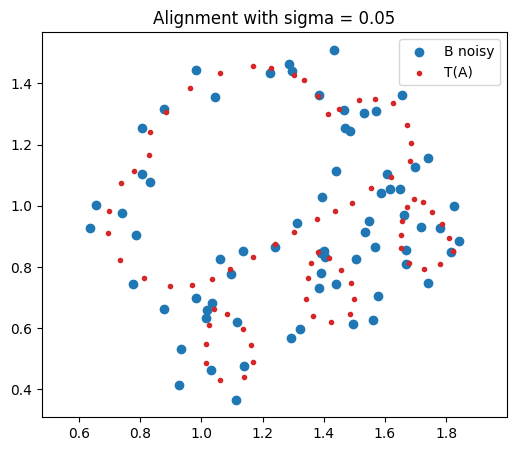

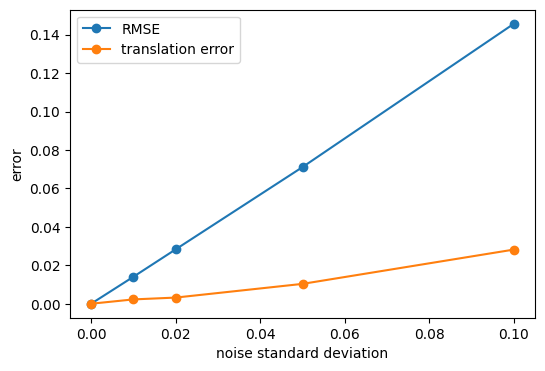

**Question.** Look at the table and the second plot, and answer in a few sentences. Why does the RMSE not go to zero? How does it compare with $\sigma$? Which is smaller, the RMSE or the translation error, and why?

**Answer.** *Write your answer here.*


## Questions

Each question has the same format. Write the experiment described under **What you have to do** in the code cell, run it, and write your answer in the text cell below it. Base your answer on your results, and explain why they happen.

### Question 1: Order of the transformations (3 points: 1 code, 2 written)

In Exercise 4 we translate last. Now translate first: $B_{alt} = s R (A + t)$, with the same $s$, $R$ and $t$.

**What you have to do**, in the cell below:

1. Compute `B_alt` $= s R (A + t)$ using `s_true`, `R_true` and `t_true`.
2. Call `procrustes(A, B_alt)` and store the result in `s_alt, R_alt, t_alt`.
3. Compute `aligned`, by applying the recovered parameters to `A` with `apply_similarity`.
4. Compute `wrong_order`, by plugging the same parameters into the wrong formula, $s R (A + t)$. This is a deliberate mistake, to show what the parameters mean.

The cell then prints the values you need and draws three plots: `B` against `B_alt`, the alignment found by Procrustes, and the same parameters used with the wrong formula. Answer these questions:

**(a)** Does `procrustes` still align the shapes exactly? Why?

**(b)** Does it recover the same $s$, $R$ and $t$? If a value is different, write it as a function of the true parameters.

**(c)** Procrustes returns its parameters for the formula $s R x + t$. Suppose we use them with a different formula, $s R (A + t)$. Why is the result wrong, even though the parameters are correct?

In [ ]:
#### START OF YOUR SOLUTION ####
# Define: B_alt, s_alt, R_alt, t_alt, aligned, wrong_order
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

print('(a) RMSE:', rmse(aligned, B_alt))
print('(b) scale:', s_alt, ', angle:', rotation_angle(R_alt))
print('    recovered t:', t_alt)
print('    s R t      :', s_true * R_true @ t_true)
print('(c) RMSE with the wrong order:', rmse(wrong_order, B_alt))

panels = [
    (B, 'B (translate last)', B_alt, 'B_alt (translate first)', 'Same s, R, t, different order'),
    (B_alt, 'B_alt', aligned, 'T(A), s R x + t', 'Procrustes result, formula s R x + t'),
    (B_alt, 'B_alt', wrong_order, 's R (A + t)', 'Same result, wrong formula s R (A + t)'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, (X, label_x, Y, label_y, title) in zip(axes, panels):
    ax.scatter(X[:, 0], X[:, 1], color='tab:blue', label=label_x)
    ax.scatter(Y[:, 0], Y[:, 1], color='tab:red', marker='.', label=label_y)
    ax.set_aspect('equal')
    ax.set_title(title)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08))
plt.show()

### Expected result

These values do not depend on randomness, so your result should match, apart from tiny numerical differences such as the digits of values close to $10^{-16}$.

```text
(a) RMSE: 4.072739767338403e-16
(b) scale: 1.5000000000000004 , angle: 29.999999999999996
    recovered t: [0.92403811 1.39951905]
    s R t      : [0.92403811 1.39951905]
(c) RMSE with the wrong order: 1.3540811111483682
```

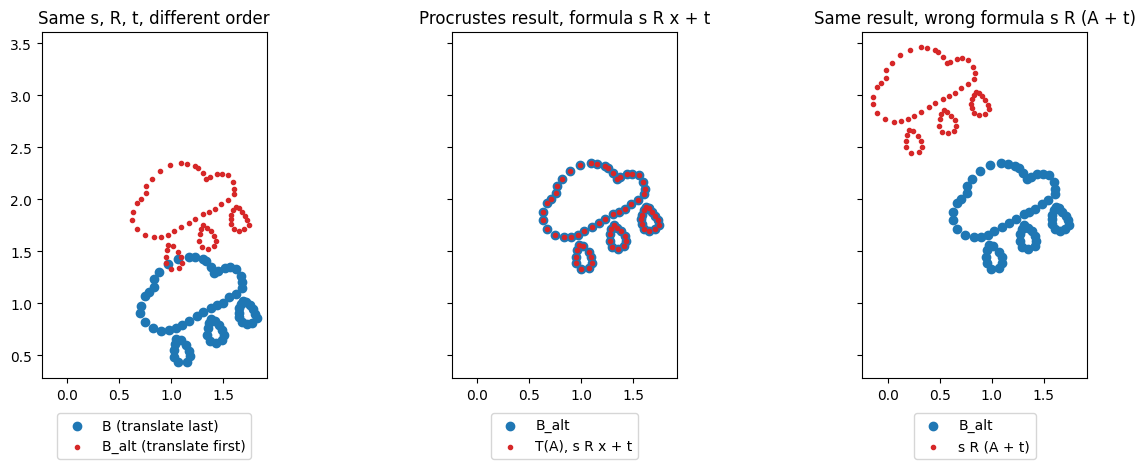

**Answer.** *Write your answer here.*


### Question 2: Reflection (3 points: 1 code, 2 written)

Mirror the target, so that it can no longer be reached from $A$ by a rotation.

**What you have to do**, in the cell below:

1. Compute `B_refl` by multiplying the x-coordinate of every point of `B` by $-1$.
2. Call `procrustes(A, B_refl)` and store the result in `s_rot, R_rot, t_rot`. Compute `aligned_rot` by applying them to `A`.
3. Call `procrustes(A, B_refl, allow_reflection=True)` and store the result in `s_ref, R_ref, t_ref`. Compute `aligned_ref` by applying them to `A`.

The cell then prints $\det(R)$, the scale and the RMSE of both runs. Answer these questions:

**(a)** Does the default `procrustes` align the shapes? What happens to the scale, and why?

**(b)** What changes with `allow_reflection=True`?

**(c)** Is the $R$ found with `allow_reflection=True` a rotation? Why?

In [ ]:
#### START OF YOUR SOLUTION ####
# Define: B_refl, s_rot, R_rot, t_rot, s_ref, R_ref, t_ref, aligned_rot, aligned_ref
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

print(f'rotation only     : det(R) = {np.linalg.det(R_rot):+.3f}, scale = {s_rot:.4f}, RMSE = {rmse(aligned_rot, B_refl):.6f}')
print(f'reflection allowed: det(R) = {np.linalg.det(R_ref):+.3f}, scale = {s_ref:.4f}, RMSE = {rmse(aligned_ref, B_refl):.6f}')
plot_clouds(B_refl, aligned_rot, 'B reflected', 'T(A)', 'Best alignment with a rotation')

### Expected result

These values do not depend on randomness, so your result should match, apart from tiny numerical differences such as the digits of values close to $10^{-16}$.

```text
rotation only     : det(R) = +1.000, scale = 0.2668, RMSE = 0.411432
reflection allowed: det(R) = -1.000, scale = 1.5000, RMSE = 0.000000
```

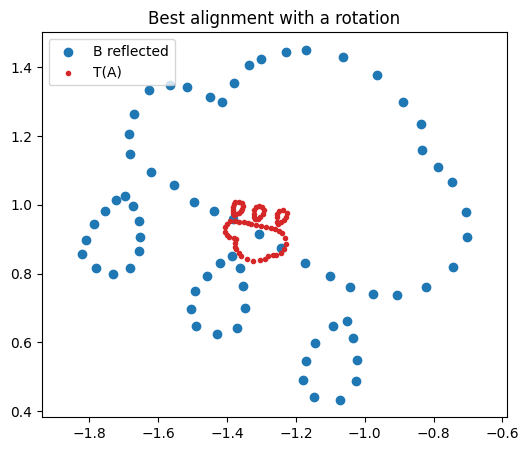

**Answer.** *Write your answer here.*


### Question 3: Permutation (3 points: 1 code, 2 written)

Shuffle the rows of the target, so that $B[i]$ no longer corresponds to $A[i]$. The set of points is the same, only their order changes.

**What you have to do**, in the cell below:

1. Use `rng.permutation(len(A))` to shuffle the rows of `B`, and call the result `B_perm`.
2. Call `procrustes(A, B_perm)`, compute `aligned_perm`, and print the recovered scale and the RMSE against `B_perm`.
3. Check that `B_perm` and `B` contain the same points, by comparing them after `np.sort(..., axis=0)`.
4. For `n_pairs` in `[0, 1, 2, 5, 10, 20, 35]`: copy `B`, swap `n_pairs` random pairs of rows that do not overlap, call `procrustes(A, ...)` on the copy, and print the number of pairs, the scale and the RMSE. Hint: take the pairs from consecutive entries of a random permutation of the indices.

Answer these questions:

**(a)** Does `procrustes` still align the shapes, even though the set of points is unchanged? What happens to the recovered scale, and why?

**(b)** Does it fail for every permutation? How does the result change with the number of swapped pairs?

**(c)** What does this tell you about what Procrustes needs as input?

In [ ]:
#### START OF YOUR SOLUTION ####
rng = np.random.default_rng(0)
# Follow the list above: print the scale and the RMSE for B_perm, the comparison of the two point sets, and one line for each n_pairs.
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

plot_clouds(B_perm, aligned_perm, 'B permuted', 'T(A)', 'Alignment with permuted points')

### Expected result

**This result may vary due to randomness.** The permutation and the swapped pairs are random, so your values can differ, especially for small numbers of pairs, where it matters which points are swapped. What should stay the same: the scale falls far below 1.5, the RMSE is around 0.4 for a full shuffle, and both errors grow with the number of swapped pairs.

```text
(a) scale = 0.0755 (true: 1.5), RMSE = 0.4176
    same point set: True
(b) swapped pairs, scale, RMSE
     0  1.5000  0.0000
     1  1.4987  0.0171
     2  1.3956  0.1532
     5  1.2512  0.2306
    10  1.0636  0.2948
    20  0.6289  0.3796
    35  0.1472  0.4161
```

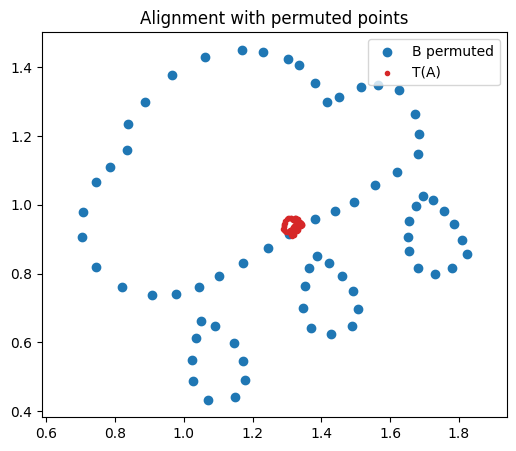

**Answer.** *Write your answer here.*


# Part 3: ICP for SMPL (44 points)

**Goal**: in Part 2 we were told which point matches which. Real data does not come with this information. Iterative Closest Point (ICP) estimates the correspondences and the transformation together, by alternating between the two.

You will do six things:

7. Find correspondences between two point clouds.
8. Implement ICP and recover a transformation.
9. Apply ICP to SMPL body models and visualize the results.
10. Fit SMPL to real 3D scans using the same idea.
11. Add a pose prior to the fit.
12. Add a shape prior to the fit.

This part uses `apply_similarity`, `procrustes` and `rmse` from Part 2, so run Part 2 first. It does not use Part 1.

**Run this cell. No code needed.**

It loads the libraries and defines the data of this part. The `data/` folder and `base_fitter.py` must be next to this notebook:

- `data/scans/<id>.obj`: a 3D scan of a person.
- `data/scans/<id>_smpl.obj`: the ground truth SMPL registration of that scan. All SMPL meshes have 6890 vertices in the same order.
- `data/smpl/SMPL_NEUTRAL.pkl`: the SMPL body model.

In [ ]:

import importlib.util
import subprocess
import sys

for package in ('scipy', 'trimesh', 'smplx'):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

import torch
import trimesh
from scipy.spatial import cKDTree

from base_fitter import SMPLFitter

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)

# The person in SCAN_A stands in a pose close to the SMPL T-pose, the person in SCAN_B has the arms down
SCAN_A = '125611500511320'
SCAN_B = '125611502399807'


def load_vertices(path):
    """Load mesh vertices without changing their order."""
    return np.array(trimesh.load_mesh(path, process=False).vertices)


def plot_bodies(X, Y, label_x='X', label_y='Y', title=None, max_points=3000):
    """Show two 3D point sets from the front and from the side."""
    rng_plot = np.random.default_rng(0)
    X_plot = X[rng_plot.permutation(len(X))[:max_points]]
    Y_plot = Y[rng_plot.permutation(len(Y))[:max_points]]
    fig, axes = plt.subplots(1, 2, figsize=(9, 5), sharey=True)
    for ax, axis, name in zip(axes, (0, 2), ('x-y view', 'z-y view')):
        ax.scatter(X_plot[:, axis], X_plot[:, 1], s=1, color='tab:blue', label=label_x)
        ax.scatter(Y_plot[:, axis], Y_plot[:, 1], s=1, color='tab:red', label=label_y)
        ax.set_aspect('equal')
        ax.set_title(name)
    axes[0].legend(loc='upper center', bbox_to_anchor=(1.05, -0.06), ncol=2, markerscale=6)
    if title:
        fig.suptitle(title)
    plt.show()


def rotation_y(degrees):
    """3D rotation around the vertical axis of the body."""
    theta = np.radians(degrees)
    return np.array([[ np.cos(theta), 0, np.sin(theta)],
                     [ 0,             1, 0            ],
                     [-np.sin(theta), 0, np.cos(theta)]])


## Exercise 7: Find correspondences (4 points: 3 code, 1 written)

Without known correspondences, the simplest guess is to match each point to its closest point in the other cloud: for each $p_i \in P$,

$$c(i) = \arg\min_j \| p_i - q_j \|_2 .$$

The cell builds a source cloud `P` for you. `P` is a rotated and shifted copy of every second point of `A`, in shuffled order, and the target is `Q = A`. So `P` has fewer points than `Q`, and `true_matches[i]` holds the index in `Q` of the point that `P[i]` really comes from. ICP will not know this array; we only use it to measure the quality of the matches.

**What you have to do**, in the cell below:

1. Write `find_correspondences(P, Q)`. `P` has shape $(N, d)$ and `Q` has shape $(M, d)$, and $N$ and $M$ can differ. It returns two arrays of length $N$: `indices`, where `indices[i]` is the index of the closest point of `Q` to `P[i]`, and `distances`, the distance to that point. The scans in Exercise 10 have many points, so do not build the full distance matrix: use `cKDTree` from `scipy.spatial`.
2. Compute `matches, distances` for `P` and `Q`.
3. Compute `correct`, the fraction of points for which `matches` equals `true_matches`.

The cell then prints `correct` and draws each match as a grey line. Then answer the question below the cell.

In [ ]:

s_p, R_p, t_p = 1.0, rotation_matrix(20), np.array([0.15, 0.1])

rng = np.random.default_rng(1)
Q = A
keep = rng.permutation(np.arange(0, len(A), 2))
true_matches = keep
P = apply_similarity(A[keep], s_p, R_p, t_p)

#### START OF YOUR SOLUTION ####
def find_correspondences(P, Q):
    """
    Find the closest point of Q for each point of P.
    :param P: (N, d) points
    :param Q: (M, d) points
    :return: indices (N,) into Q, and distances (N,)
    """
    # YOUR CODE HERE
    raise NotImplementedError()


# Define: matches, distances, correct
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

print(f'{len(P)} points, correct matches: {100 * correct:.1f}%')

plt.figure(figsize=(6, 5))
plt.plot(np.stack([P[:, 0], Q[matches, 0]]), np.stack([P[:, 1], Q[matches, 1]]), color='grey', linewidth=1)
plt.scatter(Q[:, 0], Q[:, 1], color='tab:red', label='Q')
plt.scatter(P[:, 0], P[:, 1], color='tab:blue', label='P')
plt.axis('equal')
plt.legend()
plt.title('Closest-point matches')
plt.show()


### Expected result

The cloud `P` is built with a fixed random seed, so your result should match if you keep the provided code.

```text
35 points, correct matches: 2.9%
```

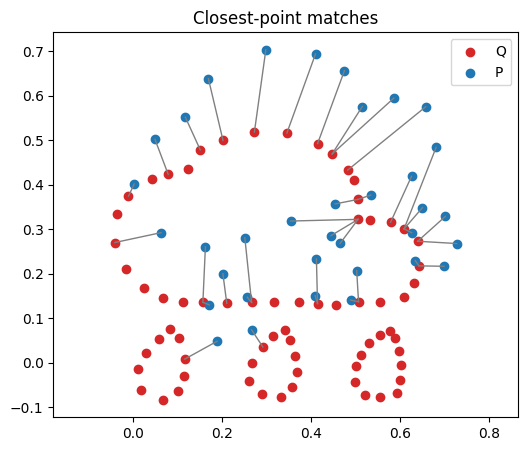

**Question 4.** Look at the plot and the printed value. Are closest-point matches correct before the shapes are aligned? If many are wrong, why can they still be useful for aligning the shapes?

**Answer.** *Write your answer here.*


## Exercise 8: Implement ICP (10 points: 8 code, 2 written)

ICP alternates two steps that you have already implemented:

1. **Correspondences**: match each point of the current source to its closest point in the target.
2. **Transformation**: run Procrustes on these pairs and move the source.

Each step reduces the sum of squared distances, so the error can only decrease, but it can stop in a local minimum.

**What you have to do**, in the cell below:

1. Write `icp(P, Q, n_iterations=30, estimate_scale=True)`. It returns `s, R, t, history`, where `s`, `R`, `t` is the **total** transformation from the original `P` to `Q`, and `history` lists the error of each iteration. It must:
    - start from `s = 1`, `R` the identity and `t` the difference of the centroids, $\bar{q} - \bar{p}$;
    - at each iteration, apply the current total transformation to `P`, and call `find_correspondences`;
    - append to `history` the root mean squared closest-point distance, $\sqrt{\frac{1}{N}\sum_i d_i^2}$;
    - run `procrustes` between the current points and their matches, to get a step `s_step, R_step, t_step`;
    - if `estimate_scale` is `False`, set `s_step = 1` and recompute `t_step` as $\bar{y} - R\,\bar{x}$, where $\bar{x}$ and $\bar{y}$ are the means of the current points and of their matches. Procrustes in Part 2 always estimates a scale, and this removes it;
    - update the total transformation. If $x \mapsto s R x + t$ is followed by the step, then $s \leftarrow s_{step}\, s$, $R \leftarrow R_{step} R$ and $t \leftarrow s_{step} R_{step} t + t_{step}$.
2. Call `icp(P, Q, estimate_scale=False)`, because `P` was built without scaling, and store the result in `s_icp, R_icp, t_icp, history`.
3. Compute `P_aligned` by applying the result to `P`.

`P` was made from `A` by a known transformation, so ICP should recover its inverse. The rest of the cell checks this, and all the `assert`s must pass. Then answer the question below the cell.

In [ ]:

#### START OF YOUR SOLUTION ####
def icp(P, Q, n_iterations=30, estimate_scale=True):
    """
    Align P to Q without known correspondences.
    :param P: (N, d) source points
    :param Q: (M, d) target points
    :param n_iterations: number of iterations
    :param estimate_scale: if False, only rotation and translation are estimated
    :return: s, R, t of the total transformation, and the list of errors
    """
    # YOUR CODE HERE
    raise NotImplementedError()


# Define: s_icp, R_icp, t_icp, history, P_aligned
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

matches_after, _ = find_correspondences(P_aligned, Q)
print(f'correct matches: {100 * np.mean(matches_after == true_matches):.1f}%')
print('final error:', history[-1])
print('recovered angle:', rotation_angle(R_icp), '(expected: -20)')

assert np.all(matches_after == true_matches)
assert rmse(P_aligned, Q[true_matches]) < 1e-8
assert np.isclose(rotation_angle(R_icp), -20)

plot_clouds(Q, P_aligned, 'Q', 'P aligned', 'ICP result')

plt.figure(figsize=(6, 3))
plt.plot(history, 'o-')
plt.xlabel('iteration')
plt.ylabel('closest-point error')
plt.yscale('symlog', linthresh=1e-6)
plt.show()


### Expected result

These values do not depend on randomness, so your result should match, apart from tiny numerical differences such as the digits of values close to $10^{-16}$. The exact iteration at which the error drops depends only on the provided data, so it should match too.

```text
correct matches: 100.0%
final error: 1.5392663585215677e-16
recovered angle: -19.999999999999996 (expected: -20)
```

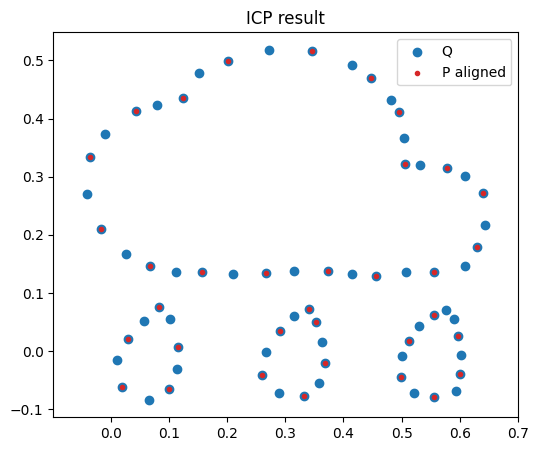

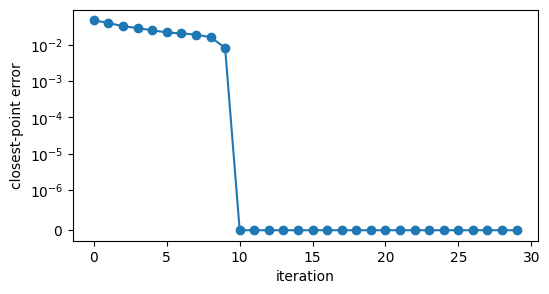

**Question 5.** Compare with Exercise 7. Why does ICP end with every match correct, when it started with many wrong ones? ICP's error never increases. Does that mean it always finds the right alignment?

**Answer.** *Write your answer here.*


## Exercise 9: ICP on SMPL models (7 points: 3 code, 4 written)

Now we align two human bodies in 3D. We use two SMPL meshes, so we know something ICP does not: vertex $i$ is the same body point on both meshes. This gives us an exact measure of the result, and a comparison with Procrustes, which uses these correspondences.

`target` is the SMPL mesh of `SCAN_A`. The experiments are:

| Name | Source | What it tests |
|---|---|---|
| `rotated 30` | `target` rotated by 30 degrees and shifted | an easy rigid motion |
| `rotated 90` | `target` rotated by 90 degrees and shifted | a larger rigid motion |
| `rotated 180` | `target` rotated by 180 degrees and shifted | a very large rigid motion |
| `other person` | SMPL mesh of `SCAN_B`, a different person in a different pose | a motion that is not rigid |

**What you have to do**, in the cell below:

1. Write `mean_vertex_error(X, Y)`, the mean Euclidean distance between corresponding vertices, $\frac{1}{N}\sum_i \|x_i - y_i\|_2$.
2. Write `align_with_icp(source, target, estimate_scale=False)`, which calls `icp` and returns the aligned source.
3. Write `align_with_procrustes(source, target)`, which calls `procrustes` and returns the aligned source.
4. Fill the dictionary `results`: for each experiment, store the aligned sources of the three methods under the keys `icp`, `icp with scale` and `procrustes`. For `icp with scale`, use `estimate_scale=True`.

The rest of the cell prints the mean vertex error of each method and plots the ICP results. Then answer the question below the cell. Errors are in metres.

In [ ]:

target = load_vertices(f'data/scans/{SCAN_A}_smpl.obj')
shift = np.array([0.3, 0.1, -0.2])

experiments = {
    'rotated 30': apply_similarity(target, 1.0, rotation_y(30), shift),
    'rotated 90': apply_similarity(target, 1.0, rotation_y(90), shift),
    'rotated 180': apply_similarity(target, 1.0, rotation_y(180), shift),
    'other person': load_vertices(f'data/scans/{SCAN_B}_smpl.obj'),
}

#### START OF YOUR SOLUTION ####
def mean_vertex_error(X, Y):
    # YOUR CODE HERE
    raise NotImplementedError()


def align_with_icp(source, target, estimate_scale=False):
    # YOUR CODE HERE
    raise NotImplementedError()


def align_with_procrustes(source, target):
    # YOUR CODE HERE
    raise NotImplementedError()


# Fill the dictionary results: results[name] = {'icp': ..., 'icp with scale': ..., 'procrustes': ...} for each experiment.
# YOUR CODE HERE
raise NotImplementedError()
#### END YOUR SOLUTION ####

print(f"{'experiment':<15}{'before':>10}{'icp':>10}{'icp+scale':>11}{'procrustes':>12}")
for name, source in experiments.items():
    r = results[name]
    print(f"{name:<15}{mean_vertex_error(source, target):>10.4f}{mean_vertex_error(r['icp'], target):>10.4f}"
          f"{mean_vertex_error(r['icp with scale'], target):>11.4f}{mean_vertex_error(r['procrustes'], target):>12.4f}")

for name in experiments:
    plot_bodies(target, results[name]['icp'], 'target', 'ICP result', f'ICP: {name}')
plot_bodies(target, results['rotated 90']['icp with scale'], 'target', 'ICP result', 'ICP with scale: rotated 90')
plot_bodies(target, results['other person']['procrustes'], 'target', 'Procrustes result', 'Procrustes: other person')


### Expected result

ICP and Procrustes are deterministic, so the table should match to the digits shown. The plots show a random subset of the points, chosen with a fixed seed.

```text
experiment         before       icp  icp+scale  procrustes
rotated 30         0.3831    0.0000     0.0000      0.0000
rotated 90         0.4758    0.0000     0.4175      0.0000
rotated 180        0.5615    0.4953     0.4627      0.0000
other person       0.1431    0.1213     0.1228      0.1269
```

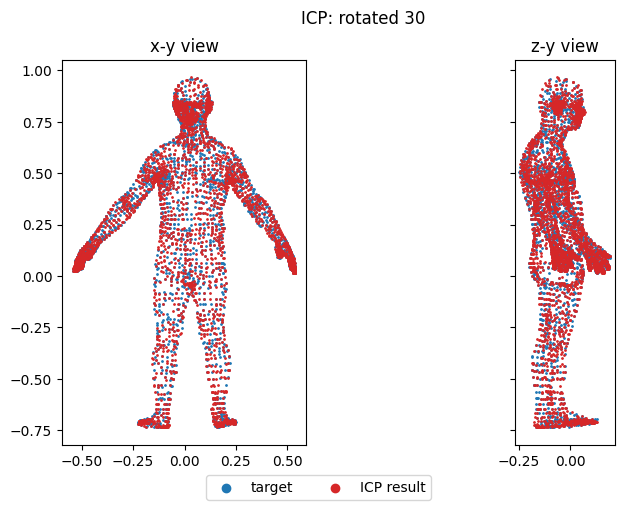

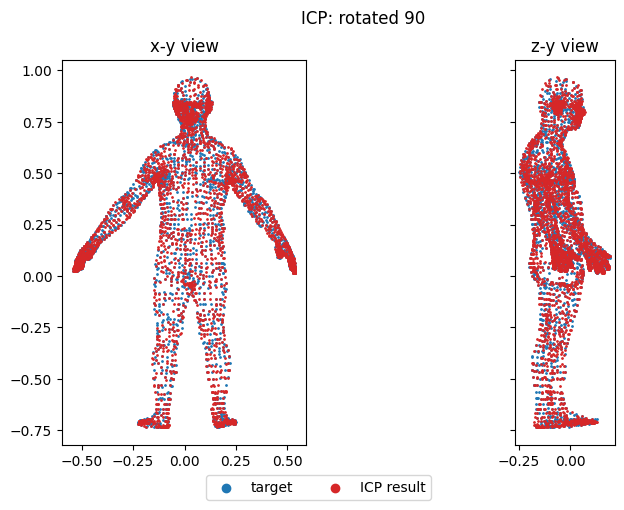

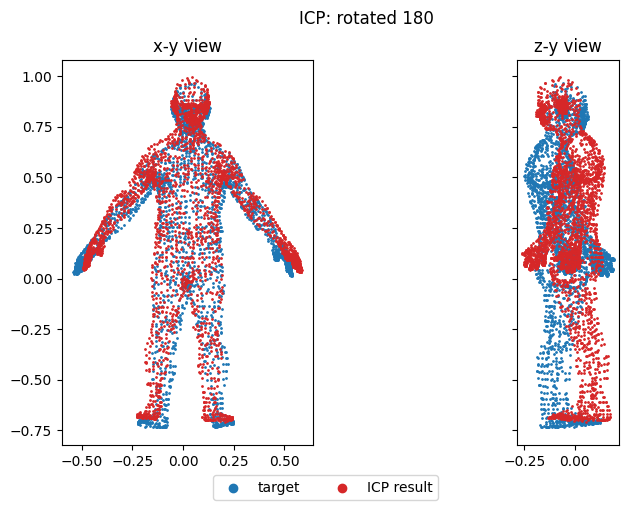

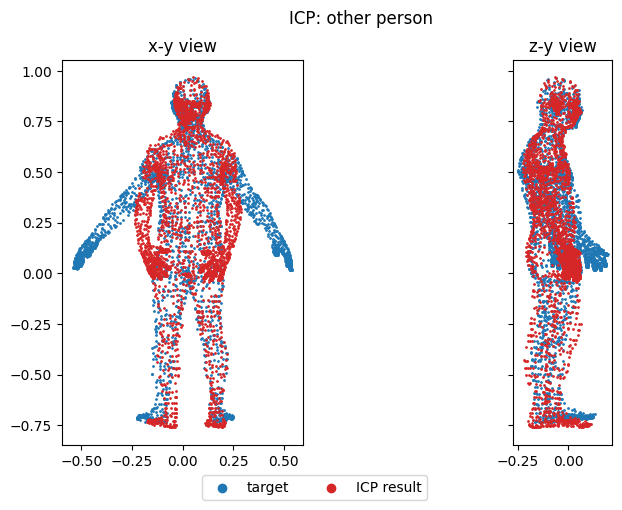

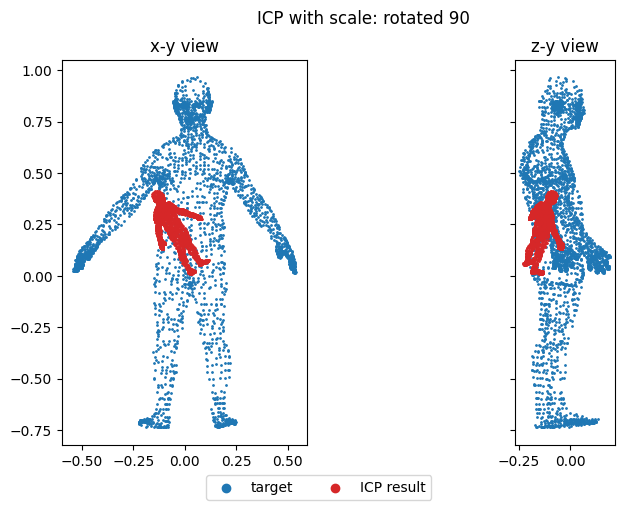

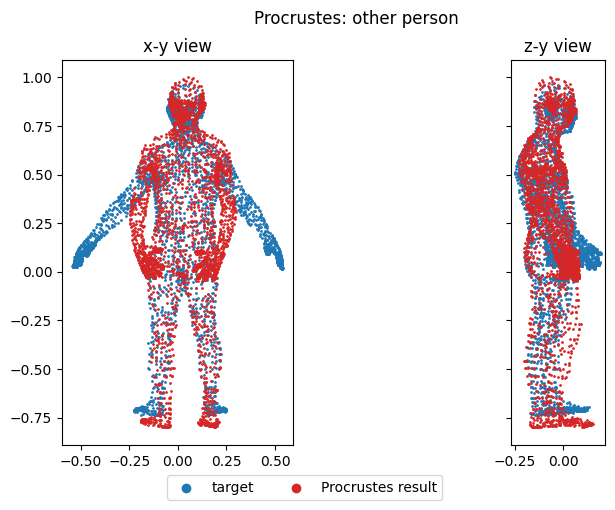

**Question 6.** Use the table and the plots.

**(a)** ICP solves `rotated 30` but not `rotated 180`, although both are the same kind of motion, and Procrustes solves both. Why?

**(b)** Compare `icp` and `icp with scale` on `rotated 90`. What goes wrong when the scale is estimated, and why? Why does the problem not appear on `rotated 30`?

**(c)** On `other person`, compare ICP with Procrustes, and look at the arms. Why can neither of them match the two bodies?

**Answer.** *Write your answer here.*


## Exercise 10: Fit SMPL to scans with ICP (11 points: 7 code, 4 written)

A rigid transformation cannot move the arms, as you saw in Exercise 9. SMPL can: its vertices are a function $M(\Phi)$ of its parameters $\Phi = \{\theta, \beta, t\}$ (pose, shape and translation). So we keep the ICP idea and change what we optimize. The transformation step of ICP had a closed-form solution, but here we use gradient descent:

$$\Phi^* = \arg\min_{\Phi} \sum_i \| x_i - s_{c(i)} \|_2^2, \qquad x_i \in M(\Phi)$$

where $s_{c(i)}$ is the scan vertex closest to the SMPL vertex $x_i$. At each iteration the matches are found again with the current vertices, then the optimizer takes one step.

We need two measures of quality:

**Chamfer distance** compares two surfaces through closest points, in both directions. With $X$ and $Y$ sampled from the two surfaces,

$$CD(X, Y) = \frac{1}{|X|}\sum_{x \in X} \min_{y \in Y} \|x - y\|_2 + \frac{1}{|Y|}\sum_{y \in Y} \min_{x \in X} \|x - y\|_2 .$$

**Vertex-to-vertex (v2v) error** compares the fit with the ground truth SMPL registration, using `mean_vertex_error`. It uses the true correspondences, so unlike Chamfer it notices when a surface is covered by the wrong body part.

The function `fit_scan` below is provided. It runs the optimization using `SMPLFitter` from `base_fitter.py`, which calls your loss at every iteration, then evaluates the result. Read it before you start.

**What you have to do**, in the cell below:

1. Write `compute_loss(data_dict)`. `data_dict['smpl']` is the SMPL model and `data_dict['scan_verts']` is a tensor of the scan vertices, of shape $(N_s, 3)$. It must:
    - call `smpl = data_dict['smpl']` and `output = smpl()`. The vertices are in `output.vertices`, of shape $(1, 6890, 3)$;
    - find the matches with your `find_correspondences`. It works on NumPy arrays, so use `.detach().cpu().numpy()` on both inputs;
    - return `{'icp': loss}`, where `loss` is the **sum** of the squared distances between each vertex and its matched scan vertex. Compute it with torch operations on the original vertices, or no gradient will reach the parameters. The matches themselves are not differentiated.
2. Write `evaluate_chamfer(mesh, scan, num_samples=10000)`. Sample `num_samples` points from each mesh with `trimesh.sample.sample_surface(mesh, num_samples)[0]`, and compute the Chamfer distance with `find_correspondences`. Return a float.

The next cell runs the fits. Run it after this one.

In [ ]:

#### START OF YOUR SOLUTION ####
def compute_loss(data_dict):
    """
    One-directional Chamfer loss from the SMPL vertices to the scan.
    :param data_dict: the data prepared in SMPLFitter.fit_scan
    :return: a dictionary of losses
    """
    # YOUR CODE HERE
    raise NotImplementedError()


def evaluate_chamfer(mesh, scan, num_samples=10000):
    """
    Compute the Chamfer distance between two meshes.
    :param mesh: fitted SMPL mesh
    :param scan: scan mesh
    :param num_samples: number of points sampled from each surface
    :return: the Chamfer distance
    """
    # YOUR CODE HERE
    raise NotImplementedError()
#### END YOUR SOLUTION ####


def fit_scan(scan_id, lr=0.01, iterations=1000, loss_func=compute_loss, loss_weights=None):
    """
    Fit SMPL to a scan and evaluate the result. No code needed.
    :param loss_func: the loss, a function of data_dict
    :param loss_weights: the weight of each key returned by loss_func
    :return: a dictionary with the fitted vertices, the scan vertices, the final loss and the two errors
    """
    scan_path = f'./data/scans/{scan_id}.obj'
    scan = trimesh.load_mesh(scan_path)
    opt_params = {'iterations': iterations, 'lr': lr, 'loss_weights': loss_weights or {'icp': 1.0}}

    fitter = SMPLFitter('./data/smpl', './data/priors', device=DEVICE)
    smpl = fitter.fit_scan(loss_func, opt_params, scan, scan_path, 'neutral', 'output', f'_lr-{lr}')

    with torch.no_grad():
        vertices = smpl().vertices[0].cpu().numpy()
    mesh = trimesh.Trimesh(vertices, smpl.faces, process=False)
    ground_truth = load_vertices(f'data/scans/{scan_id}_smpl.obj')

    np.random.seed(0)  # the surface sampling is random
    return {'vertices': vertices, 'scan': np.array(scan.vertices),
            'loss': float(np.sum(find_correspondences(vertices, np.array(scan.vertices))[1] ** 2)),
            'chamfer': evaluate_chamfer(mesh, scan), 'v2v': mean_vertex_error(vertices, ground_truth)}


**Run this cell. No code needed, but it uses your functions above.** It fits SMPL to both scans with three learning rates, prints the errors, and shows the fits for the learning rate of 0.01. Each fit takes about 10 seconds on a CPU. In the plots, the scan is blue and the fitted model is red. A good fit has red points all over the blue body, including the arms.

In [ ]:

fits = {}
for scan_id, name in ((SCAN_A, 'pose close to T-pose'), (SCAN_B, 'arms down')):
    for lr in (0.1, 0.01, 0.001):
        fits[name, lr] = fit_scan(scan_id, lr=lr)

print(f"{'scan':<24}{'lr':>7}{'ICP loss':>10}{'Chamfer':>10}{'v2v':>10}")
for (name, lr), fit in fits.items():
    print(f"{name:<24}{lr:>7}{fit['loss']:>10.3f}{fit['chamfer']:>10.4f}{fit['v2v']:>10.4f}")

for name in ('pose close to T-pose', 'arms down'):
    fit = fits[name, 0.01]
    plot_bodies(fit['scan'], fit['vertices'], 'scan', 'fitted SMPL', f'{name}, lr = 0.01')


### Expected result

The fit itself is repeatable on one machine, but small differences are normal: the Chamfer distance samples random points, and the optimization can differ slightly between machines and between CPU and GPU. Expect the same behaviour and similar values.

```text
scan                         lr  ICP loss   Chamfer       v2v
pose close to T-pose        0.1     2.190    0.0653    0.1873
pose close to T-pose       0.01     0.799    0.0235    0.0173
pose close to T-pose      0.001     2.651    0.0375    0.0367
arms down                   0.1     2.132    0.2001    0.4632
arms down                  0.01     3.179    0.0968    0.3893
arms down                 0.001    15.096    0.1081    0.4113
```

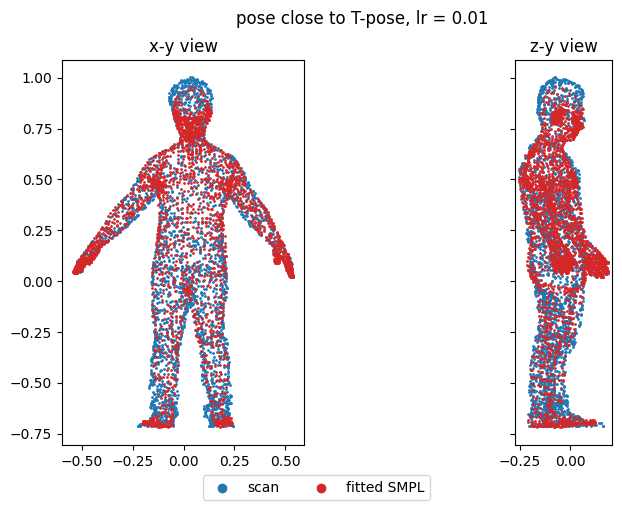

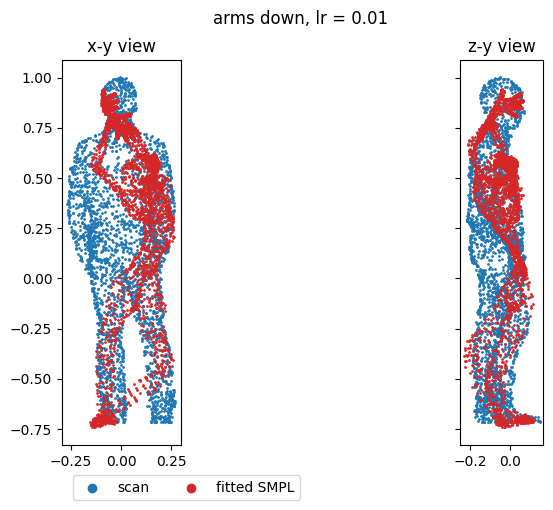

**Question 7.** Use the table and the plots.

**(a)** ICP works on one scan and fails on the other. What is the difference between them, and what does this say about ICP?

**(b)** How does the learning rate affect the result on the scan that works?

**(c)** On the scan that fails, compare the ICP loss, the Chamfer distance and v2v with the values of the scan that works. Which one shows the failure most clearly, and why? What could we add to the optimization to avoid this failure?

**Answer.** *Write your answer here.*


## Exercise 11: Pose prior (7 points: 4 code, 3 written)

In Exercise 10 the arms-down fit ended in a twisted pose that no person could take, because the ICP loss has no notion of what a body can do. We can add this knowledge with a **prior**, an extra loss term that penalizes unlikely parameters.

We model natural poses with a Gaussian distribution with mean $\mu$ and covariance $\Sigma$, learned from real poses. The negative log-likelihood of a Gaussian is, up to a constant and a factor, the **squared** Mahalanobis distance of the pose $\theta$ to the distribution, so this is our loss:

$$L_{pose} = d_M^2(\theta) = (\theta - \mu)^T \Sigma^{-1} (\theta - \mu)$$

We are given the Cholesky factor $L$ of the precision matrix, a lower-triangular matrix with $\Sigma^{-1} = L L^T$. This gives a simple way to compute the loss, without inverting anything:

$$(\theta - \mu)^T L L^T (\theta - \mu) = \| (\theta - \mu)^T L \|^2$$

The total loss is now a weighted sum, $L_{icp} + \lambda_{pose} L_{pose}$, and the weight $\lambda_{pose}$ decides how much the prior counts.

**What you have to do**, in the cell below:

1. Write `pose_prior_loss(data_dict)`, which returns $L_{pose}$ as a scalar tensor. You need:
    - `data_dict['smpl'].body_pose`, of shape $(1, 69)$. The prior only covers the first 63 values, so use `body_pose[:, :63]`;
    - `data_dict['body_prior']['mean']`, which is $\mu$, of shape $(1, 63)$;
    - `data_dict['body_prior']['prec_chole']`, which is $L$, of shape $(63, 63)$.
2. Write `compute_loss_with_pose_prior(data_dict)`. It calls your `compute_loss` from Exercise 10, adds the key `'prior'` to the dictionary with the value of `pose_prior_loss`, and returns the dictionary.

The next cell runs the experiment. Then answer the question below it.

In [ ]:

#### START OF YOUR SOLUTION ####
def pose_prior_loss(data_dict):
    """
    Squared Mahalanobis distance of the body pose to the pose prior.
    :param data_dict: the data prepared in SMPLFitter.fit_scan
    :return: a scalar tensor
    """
    # YOUR CODE HERE
    raise NotImplementedError()


def compute_loss_with_pose_prior(data_dict):
    # YOUR CODE HERE
    raise NotImplementedError()
#### END YOUR SOLUTION ####


**Run this cell. No code needed, but it uses your functions above.** It fits the arms-down scan with several values of $\lambda_{pose}$, with a learning rate of 0.01, and prints and plots the errors. It stores the selected weight in `best_pose_weight`, and shows that fit. A larger weight than needed restricts the model for no benefit, so `select_weight` keeps the **smallest** weight whose v2v is within 5% of the best one.

In [ ]:

def plot_sweep(weights, sweep, xlabel):
    """Plot the errors of a list of fits against the loss weight."""
    plt.figure(figsize=(6, 3.5))
    plt.plot(weights, [fit['chamfer'] for fit in sweep], 'o-', label='Chamfer')
    plt.plot(weights, [fit['v2v'] for fit in sweep], 'o-', label='v2v')
    plt.xscale('log')
    plt.xlabel(xlabel)
    plt.ylabel('error (m)')
    plt.legend()
    plt.show()


def select_weight(weights, sweep, tolerance=0.05):
    """Return the smallest weight whose v2v is within the tolerance of the best v2v."""
    v2v = np.array([fit['v2v'] for fit in sweep])
    return min(w for w, error in zip(weights, v2v) if error <= (1 + tolerance) * v2v.min())


pose_weights = [1e-3, 1e-1, 1, 3, 10, 30, 100]
pose_sweep = [fit_scan(SCAN_B, loss_func=compute_loss_with_pose_prior, loss_weights={'icp': 1.0, 'prior': w})
              for w in pose_weights]

print(f"{'pose weight':>12}{'ICP loss':>10}{'Chamfer':>10}{'v2v':>10}")
for w, fit in zip(pose_weights, pose_sweep):
    print(f"{w:>12}{fit['loss']:>10.3f}{fit['chamfer']:>10.4f}{fit['v2v']:>10.4f}")

best_pose_weight = select_weight(pose_weights, pose_sweep)
print('best pose weight:', best_pose_weight)

plot_sweep(pose_weights, pose_sweep, 'pose prior weight')
best_fit = pose_sweep[pose_weights.index(best_pose_weight)]
plot_bodies(best_fit['scan'], best_fit['vertices'], 'scan', 'fitted SMPL', f'arms down, pose weight = {best_pose_weight}')


### Expected result

The fit itself is repeatable on one machine, but small differences are normal: the Chamfer distance samples random points, and the optimization can differ slightly between machines and between CPU and GPU. Expect the same behaviour and similar values. The curve is not smooth, because each weight can end in a different local minimum, so on a different machine the selected weight can change.

```text
pose weight  ICP loss   Chamfer       v2v
       0.001     3.428    0.0992    0.3890
         0.1     4.751    0.0753    0.3580
           1    10.492    0.0793    0.2424
           3     5.280    0.1219    0.1968
          10     4.647    0.0529    0.0666
          30     5.911    0.0901    0.1063
         100     4.945    0.0925    0.1179
best pose weight: 10
```

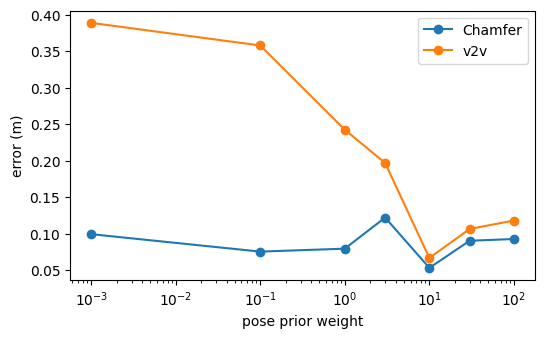

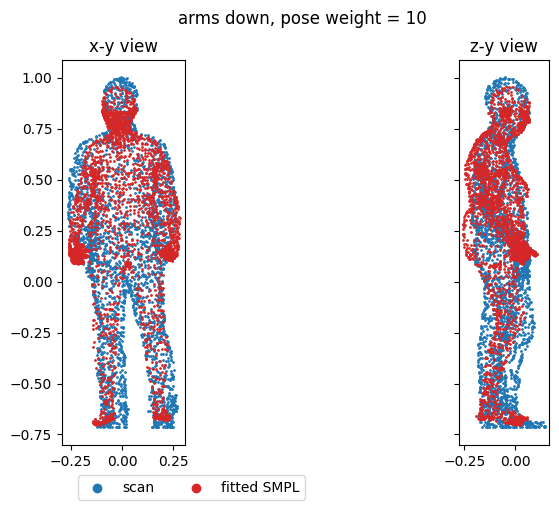

**Question 8.** Use the table and the plots.

**(a)** What happens for small, intermediate and large weights? Why does the error stop improving above a certain weight?

**(b)** Which weight has the lowest Chamfer distance, and is it the one with the lowest v2v? What does this tell you?

**(c)** Is the fit with the best weight correct? Why does a pose prior not fully solve the problem?

**Answer.** *Write your answer here.*


## Exercise 12: Shape prior (5 points: 2 code, 3 written)

The shape parameters $\beta$ need a prior too: the optimization can use extreme shapes to reach the scan with the wrong body parts. SMPL's shape space is built with PCA and scaled so that $\beta$ follows a unit Gaussian, $\mu = 0$ and $\Sigma = I$. With these values, the squared Mahalanobis distance, as in Exercise 11, is simply the squared norm of $\beta$, so the loss is

$$L_{shape} = \| \beta \|^2 = \sum_i \beta_i^2 .$$

The total loss is now $L_{icp} + \lambda_{pose} L_{pose} + \lambda_{shape} L_{shape}$.

**What you have to do**, in the cell below:

1. Write `shape_prior_loss(data_dict)`, which returns $\|\beta\|^2$ as a scalar tensor. The parameters are in `data_dict['smpl'].betas`, of shape $(1, 10)$.
2. Write `compute_loss_with_priors(data_dict)`. It calls `compute_loss_with_pose_prior`, adds the key `'shape'` with the value of `shape_prior_loss`, and returns the dictionary.

The next cell runs the experiment. Then answer the question below it.

In [ ]:

#### START OF YOUR SOLUTION ####
def shape_prior_loss(data_dict):
    """
    Squared norm of the shape parameters.
    :param data_dict: the data prepared in SMPLFitter.fit_scan
    :return: a scalar tensor
    """
    # YOUR CODE HERE
    raise NotImplementedError()


def compute_loss_with_priors(data_dict):
    # YOUR CODE HERE
    raise NotImplementedError()
#### END YOUR SOLUTION ####


**Run this cell. No code needed, but it uses your functions above.** It fits the arms-down scan with `best_pose_weight` and several values of $\lambda_{shape}$, and selects `best_shape_weight` with the same rule. Then it runs both scans with the best weights, to compare ICP alone, ICP with the pose prior, and ICP with both priors.

In [ ]:

shape_weights = [1e-1, 1, 10, 30, 100, 300]
shape_sweep = [fit_scan(SCAN_B, loss_func=compute_loss_with_priors,
                        loss_weights={'icp': 1.0, 'prior': best_pose_weight, 'shape': w})
               for w in shape_weights]

print(f"{'shape weight':>12}{'ICP loss':>10}{'Chamfer':>10}{'v2v':>10}")
for w, fit in zip(shape_weights, shape_sweep):
    print(f"{w:>12}{fit['loss']:>10.3f}{fit['chamfer']:>10.4f}{fit['v2v']:>10.4f}")

best_shape_weight = select_weight(shape_weights, shape_sweep)
print('best shape weight:', best_shape_weight)
plot_sweep(shape_weights, shape_sweep, 'shape prior weight')

methods = {
    'ICP': (compute_loss, {'icp': 1.0}),
    'ICP + pose': (compute_loss_with_pose_prior, {'icp': 1.0, 'prior': best_pose_weight}),
    'ICP + pose + shape': (compute_loss_with_priors, {'icp': 1.0, 'prior': best_pose_weight, 'shape': best_shape_weight}),
}
print(f"\n{'scan':<24}{'method':<22}{'Chamfer':>10}{'v2v':>10}")
final_fits = {}
for scan_id, name in ((SCAN_A, 'pose close to T-pose'), (SCAN_B, 'arms down')):
    for method, (loss_func, weights) in methods.items():
        fit = fit_scan(scan_id, loss_func=loss_func, loss_weights=weights)
        final_fits[name, method] = fit
        print(f"{name:<24}{method:<22}{fit['chamfer']:>10.4f}{fit['v2v']:>10.4f}")

for name in ('pose close to T-pose', 'arms down'):
    fit = final_fits[name, 'ICP + pose + shape']
    plot_bodies(fit['scan'], fit['vertices'], 'scan', 'fitted SMPL', f'{name}, both priors')


### Expected result

The fit itself is repeatable on one machine, but small differences are normal: the Chamfer distance samples random points, and the optimization can differ slightly between machines and between CPU and GPU. Expect the same behaviour and similar values. The selected weight can differ too, since the errors are almost flat for large weights.

```text
shape weight  ICP loss   Chamfer       v2v
         0.1     5.013    0.0537    0.0642
           1     5.296    0.0535    0.0605
          10     5.250    0.0526    0.0551
          30     5.188    0.0514    0.0529
         100     5.191    0.0516    0.0531
         300     5.180    0.0520    0.0530
best shape weight: 10
scan                    method                   Chamfer       v2v
pose close to T-pose    ICP                       0.0238    0.0173
pose close to T-pose    ICP + pose                0.0442    0.0517
pose close to T-pose    ICP + pose + shape        0.0480    0.0474
arms down               ICP                       0.0971    0.3893
arms down               ICP + pose                0.0529    0.0666
arms down               ICP + pose + shape        0.0519    0.0551
```

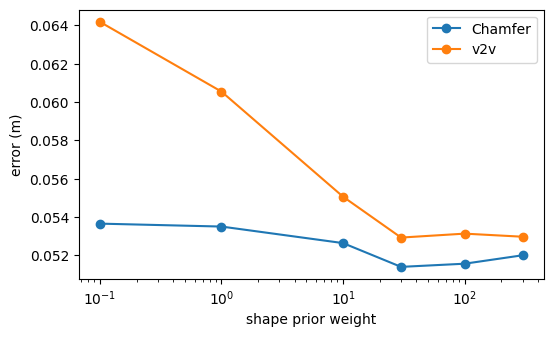

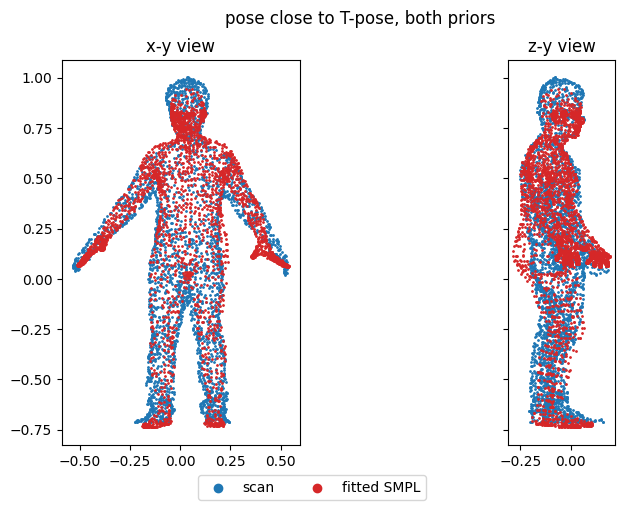

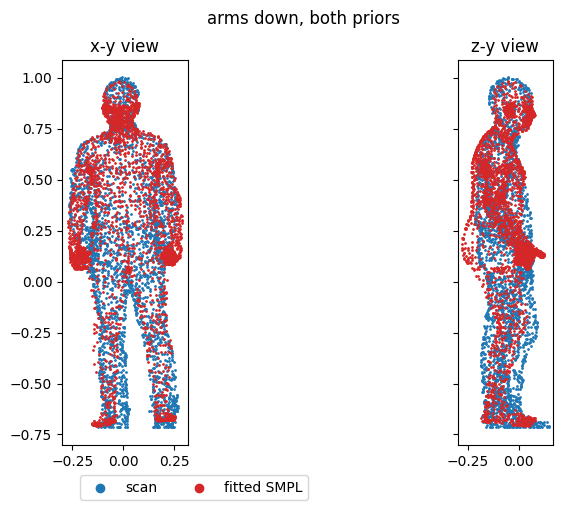

**Question 9.** Use the tables and the plots.

**(a)** Does the shape prior improve the arms-down fit? What happens with a very large weight, and why?

**(b)** Compare the three methods on the scan in a pose close to the T-pose. What is the cost of using the priors on a scan that already worked?

**(c)** After adding both priors, what is still missing? How could the remaining error be reduced?

**Answer.** *Write your answer here.*
